<a href="https://colab.research.google.com/github/carolinacollaro/GSIF_tutorials/blob/master/Random_Forest_Copernicus_to_Lidar_Yaxh%C3%A0_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install rasterio

In [3]:
import rasterio
import numpy as np
import pandas as pd

def load_raster_data(file_path):
    """Loads a raster file and returns its data and affine transform, converting nodata to NaN."""
    with rasterio.open(file_path) as src:
        data = src.read(1)
        transform = src.transform
        nodata = src.nodata
        if nodata is not None:
            data[data == nodata] = np.nan # Convert nodata values to NaN
    return data, transform, nodata

# Define file paths for target and features
LiDAR_path = '/content/LiDAR_elev_aggregated_30m.tif'
Copernicus_DSM_path = '/content/0_DSM_Copernicus_30m_mascherato.tif'
Slope_path = '/content/1.slope_DSM_Copernicus_Yaxha_30m_mascherato_gradi.tif'
Aspect_path = '/content/1.aspect_DSM_Copernicus_Yaxha_30m_mascherato.tif'
TPI_path = '/content/2.TPI_DSM_Copernicus_Yaxha_30m_mascherato_r90m.tif'
LS_path = '/content/1.LS_factor_DSM_Copernicus_Yaxha_30m_mascherato_depression_filled.tif'
TWI_path = '/content/1.TWI_DSM_Copernicus_Yaxha_30m_mascherato_depression_filled.tif'

# Load all raster data and their nodata values, converting nodata to NaN
lidar_data, lidar_transform, lidar_nodata = load_raster_data(LiDAR_path)
copernicus_dsm_data, _, copernicus_nodata = load_raster_data(Copernicus_DSM_path)
slope_data, _, slope_nodata = load_raster_data(Slope_path)
aspect_data, _, aspect_nodata = load_raster_data(Aspect_path)
tpi_data, _, tpi_nodata = load_raster_data(TPI_path)
ls_data, _, ls_nodata = load_raster_data(LS_path)
twi_data, _, twi_nodata = load_raster_data(TWI_path)

# y_target and X_features will be created after focal stats with a comprehensive mask
# For now, ensure the data is loaded and NaNs are set for NoData.

print("Raster data loaded and NoData values converted to NaN.")

Raster data loaded and NoData values converted to NaN.


In [56]:
pip install pysal

### Feature Engineering: Adding Focal Statistics

Focal statistics (or moving window operations) calculate a new value for each pixel based on the values of its neighbors within a defined window (e.g., 3x3, 5x5). This can help capture local patterns and provide context, such as identifying if a pixel is in a valley or on a ridge. We'll calculate focal mean for the Copernicus DSM and Slope layers.

In [4]:
from scipy.ndimage import uniform_filter
import numpy as np # Ensure numpy is imported for nan functions

def calculate_focal_mean(data, size=3):
    """Calculates focal mean, ignoring NoData (NaN) values."""
    # Create a mask where valid data is 1 and NaN is 0
    valid_mask = ~np.isnan(data)

    # Replace NaNs with 0 for summation, so they don't affect the sum
    data_filled = np.nan_to_num(data, nan=0.0)

    # Calculate the sum of valid values in the window
    sum_data = uniform_filter(data_filled, size=size, mode='reflect')

    # Calculate the count of valid values in the window
    count_data = uniform_filter(valid_mask.astype(float), size=size, mode='reflect')

    # Avoid division by zero where all values in the window were NaN
    # Replace 0 counts with 1 to avoid ZeroDivisionError, result will be NaN due to sum_data being 0
    count_data[count_data == 0] = np.nan # This ensures result is NaN if no valid data in window

    # Calculate the mean
    focal_mean = sum_data / count_data

    return focal_mean

# Calculate focal mean for Copernicus DSM and Slope with a 5x5 window
copernicus_dsm_focal_mean_5x5 = calculate_focal_mean(copernicus_dsm_data, size=5)
slope_focal_mean_5x5 = calculate_focal_mean(slope_data, size=5)

print("Calcolo dei livelli di media focale con finestra 5x5 (i valori NoData sono trattati come NaN e ignorati nel calcolo della media).")

Calcolo dei livelli di media focale con finestra 5x5 (i valori NoData sono trattati come NaN e ignorati nel calcolo della media).


In [5]:
# Create a comprehensive mask that excludes any pixel with NaN in *any* of the features or target
# All NoData values should now be represented as np.nan from load_raster_data

final_valid_mask = (~np.isnan(lidar_data) &
                   ~np.isnan(copernicus_dsm_data) &
                   ~np.isnan(slope_data) &
                   ~np.isnan(aspect_data) &
                   ~np.isnan(tpi_data) &
                   ~np.isnan(ls_data) &
                   ~np.isnan(twi_data) &
                   ~np.isnan(copernicus_dsm_focal_mean_5x5) &
                   ~np.isnan(slope_focal_mean_5x5))

# Apply this final_valid_mask to all data
y_target = lidar_data[final_valid_mask]
X_features = np.array([
    copernicus_dsm_data[final_valid_mask],
    slope_data[final_valid_mask],
    aspect_data[final_valid_mask],
    tpi_data[final_valid_mask],
    ls_data[final_valid_mask],
    twi_data[final_valid_mask],
    copernicus_dsm_focal_mean_5x5[final_valid_mask],
    slope_focal_mean_5x5[final_valid_mask]
]).T # Transpose to have features as columns

# Create a DataFrame for easier handling
df = pd.DataFrame(X_features, columns=[
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5'
])
df['LiDAR_Elevation'] = y_target

print(f"Shape of finally updated features (X): {X_features.shape}")
print(f"Shape of finally updated target (y): {y_target.shape}")
display(df.head())

Shape of finally updated features (X): (1487, 8)
Shape of finally updated target (y): (1487,)


,Copernicus_DSM,Slope,Aspect,TPI,LS,TWI,Copernicus_DSM_FocalMean_5x5,Slope_FocalMean_5x5,LiDAR_Elevation
0,231.976105,3.743772,286.492889,-2.497805,1.350838,7.246906,234.441275,4.467395,229.082260
1,232.242157,3.619867,99.615662,-0.617698,1.082701,7.431825,232.750593,3.370557,227.771561
2,231.343735,0.790279,175.329666,-2.412340,0.081907,15.705695,233.350555,4.322804,228.253906
3,232.531723,6.049062,276.235626,-1.934587,1.895657,6.422925,234.290869,4.573957,229.882965
4,234.894028,1.613973,330.681671,0.920631,0.366447,6.973103,233.926264,3.401404,227.608856


### Aggiunta di Feature Derivate da Immagini Satellitari Sentinel-2 (NDVI e NDWI)

Per migliorare il modello, possiamo incorporare feature derivate da immagini satellitari, come gli indici spettrali. In questo esempio, dimostreremo come aggiungere l'Normalized Difference Vegetation Index (NDVI) e l'Normalized Difference Water Index (NDWI) utilizzando dati Sentinel-2 simulati.

In [30]:
import numpy as np
import pandas as pd

# Dimensioni della griglia dei dati esistenti (es. lidar_data.shape)
# Assumiamo che lidar_data.shape sia già disponibile dal caricamento iniziale.
# Se non lo fosse, potresti caricarlo qui per ottenere la forma corretta.
grids_shape = lidar_data.shape

# Simuliamo i dati delle bande Sentinel-2 (Bande a 10m: B4-Red, B8-NIR, B3-Green)
# Questi sono array 2D con la stessa forma dei tuoi dati raster esistenti.
# In uno scenario reale, queste bande sarebbero caricate da GeoTIFF o da API.

# Banda 4 (Red) - Range di valori tipici: ~0.02 - 0.5
sentinel_red_data = np.random.uniform(0.02, 0.5, grids_shape)
# Introduciamo alcuni NaN per simulare NoData nelle immagini satellitari
sentinel_red_data[np.random.rand(*grids_shape) < 0.1] = np.nan

# Banda 8 (Near-Infrared - NIR) - Range di valori tipici: ~0.05 - 0.7
sentinel_nir_data = np.random.uniform(0.05, 0.7, grids_shape)
sentinel_nir_data[np.random.rand(*grids_shape) < 0.1] = np.nan

# Banda 3 (Green) - Range di valori tipici: ~0.01 - 0.4
sentinel_green_data = np.random.uniform(0.01, 0.4, grids_shape)
sentinel_green_data[np.random.rand(*grids_shape) < 0.1] = np.nan

print("Dati Sentinel-2 simulati (Bande Red, NIR, Green) creati con successo.")

Dati Sentinel-2 simulati (Bande Red, NIR, Green) creati con successo.


In [31]:
def calculate_ndvi(nir, red):
    """Calcola l'Normalized Difference Vegetation Index (NDVI)."""
    # Evita la divisione per zero e gestisce i NaN
    numerator = nir - red
    denominator = nir + red

    # Sostituisci i valori zero nel denominatore con NaN per evitare RuntimeWarning
    denominator = np.where(denominator == 0, np.nan, denominator)

    ndvi = numerator / denominator
    return ndvi

def calculate_ndwi(green, nir):
    """Calcola l'Normalized Difference Water Index (NDWI)."""
    # Evita la divisione per zero e gestisce i NaN
    numerator = green - nir
    denominator = green + nir

    # Sostituisci i valori zero nel denominatore con NaN per evitare RuntimeWarning
    denominator = np.where(denominator == 0, np.nan, denominator)

    ndwi = numerator / denominator
    return ndwi

# Calcola NDVI e NDWI dai dati simulati
sentinel_ndvi_data = calculate_ndvi(sentinel_nir_data, sentinel_red_data)
sentinel_ndwi_data = calculate_ndwi(sentinel_green_data, sentinel_nir_data)

print("NDVI e NDWI calcolati con successo dai dati simulati.")

NDVI e NDWI calcolati con successo dai dati simulati.


**Nota Importante sull'Acquisizione e Allineamento dei Dati Reali:**

In uno scenario reale, dovresti acquisire immagini Sentinel-2 per la tua area di interesse. Strumenti come Google Earth Engine (EE) o librerie Python come `sentinelhub` o `eodag` possono essere utilizzati per scaricare dati. Spesso, queste piattaforme offrono già bande pre-processate e indicizzate.

Dopo l'acquisizione, è FONDAMENTALE che i dati Sentinel-2 siano:
1.  **Allineati Spazialmente:** Le immagini satellitari devono coprire esattamente la stessa area geografica dei tuoi dati LiDAR e DSM. Questo può richiedere operazioni di riproiezione o ritaglio.
2.  **Risoluzione Uniforme:** I pixel di Sentinel-2 (tipicamente 10m o 20m) devono essere riscampioni (resampled) alla stessa risoluzione dei tuoi dati (es. 30m). Per questo, si utilizzano tecniche di risampling come il nearest neighbor per dati categorici o bilineare/cubica per dati continui.

Per semplicità in questa dimostrazione, assumiamo che i dati Sentinel-2 simulati siano già allineati e risampionati alla stessa griglia dei tuoi dati esistenti. Se i dati reali non sono allineati, dovrai usare librerie come `rasterio` e le sue funzionalità `resample` o `reproject` per allinearli.

In [32]:
# Aggiorna la maschera completa per includere le nuove feature Sentinel-2
# Usiamo la maschera esistente `final_valid_mask` e aggiungiamo le condizioni per NDVI e NDWI.
# `final_valid_mask` è definita nella cella precedente `c619920c`.
final_valid_mask_with_s2 = (final_valid_mask &
                           ~np.isnan(sentinel_ndvi_data) &
                           ~np.isnan(sentinel_ndwi_data))

# Applica questa nuova maschera a tutti i dati:
# 1. Target (LiDAR Elevation)
y_target_s2 = lidar_data[final_valid_mask_with_s2]

# 2. Feature esistenti + nuove feature Sentinel-2
# X_features è stata definita nella cella c619920c
X_features_s2 = np.array([
    copernicus_dsm_data[final_valid_mask_with_s2],
    slope_data[final_valid_mask_with_s2],
    aspect_data[final_valid_mask_with_s2],
    tpi_data[final_valid_mask_with_s2],
    ls_data[final_valid_mask_with_s2],
    twi_data[final_valid_mask_with_s2],
    copernicus_dsm_focal_mean_5x5[final_valid_mask_with_s2],
    slope_focal_mean_5x5[final_valid_mask_with_s2],
    sentinel_ndvi_data[final_valid_mask_with_s2], # Nuova feature: NDVI
    sentinel_ndwi_data[final_valid_mask_with_s2]  # Nuova feature: NDWI
]).T # Trasponi per avere le feature come colonne

# Aggiorna i nomi delle feature per riflettere le nuove aggiunte
feature_names_s2 = [
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5',
    'NDVI', 'NDWI' # Nuovi nomi delle feature
]

# Crea un nuovo DataFrame per una gestione più semplice con le feature aggiornate
df_s2 = pd.DataFrame(X_features_s2, columns=feature_names_s2)
df_s2['LiDAR_Elevation'] = y_target_s2

print(f"Shape delle feature aggiornate (X) con Sentinel-2: {X_features_s2.shape}")
print(f"Shape del target aggiornato (y) con Sentinel-2: {y_target_s2.shape}")
display(df_s2.head())

# Sovrascrivi le variabili globali per garantire la coerenza nelle celle successive
X_features = X_features_s2
y_target = y_target_s2
df = df_s2
final_valid_mask = final_valid_mask_with_s2 # Aggiorna la maschera globale
feature_names = feature_names_s2 # Aggiorna i nomi delle feature globali

Shape delle feature aggiornate (X) con Sentinel-2: (1088, 10)
Shape del target aggiornato (y) con Sentinel-2: (1088,)


,Copernicus_DSM,Slope,Aspect,TPI,LS,TWI,Copernicus_DSM_FocalMean_5x5,Slope_FocalMean_5x5,NDVI,NDWI,LiDAR_Elevation
0,232.242157,3.619867,99.615662,-0.617698,1.082701,7.431825,232.750593,3.370557,0.268797,-0.425546,227.771561
1,232.531723,6.049062,276.235626,-1.934587,1.895657,6.422925,234.290869,4.573957,0.212654,-0.281055,229.882965
2,234.894028,1.613973,330.681671,0.920631,0.366447,6.973103,233.926264,3.401404,0.187395,-0.782988,227.608856
3,235.086533,2.463136,98.727768,1.903722,0.524914,6.605001,233.158394,2.934901,-0.191421,-0.597925,227.536484
4,230.407852,0.977415,212.547012,-3.479351,0.233780,14.708410,233.422195,4.278025,0.279002,-0.435716,228.986862


Ora che le feature NDVI e NDWI sono state integrate nel tuo set di dati, il passo successivo sarebbe quello di riaddestrare il modello di Machine Learning (es. Random Forest o XGBoost) con questo set di feature esteso. Successivamente, dovresti rivalutare le prestazioni del modello e analizzare l'importanza delle nuove feature, come fatto in precedenza per le statistiche focali.

The dataset now includes the newly engineered focal statistics features. We will now re-run the train/test split and re-train the Random Forest model with these expanded features to see if accuracy has improved.

In [34]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (70% train, 30% test) with updated features
# Use X_features_s2 and y_target_s2 to ensure the model is trained with 10 features
X_train, X_test, y_train, y_test = train_test_split(X_features_s2, y_target_s2, test_size=0.3, random_state=42)

print(f"Shape of X_train (updated): {X_train.shape}")
print(f"Shape of X_test (updated): {X_test.shape}")
print(f"Shape of y_train (updated): {y_train.shape}")
print(f"Shape of y_test (updated): {y_test.shape}")

Shape of X_train (updated): (761, 10)
Shape of X_test (updated): (327, 10)
Shape of y_train (updated): (761,)
Shape of y_test (updated): (327,)


In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Initialize the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Train the model with updated features
print("Training Random Forest Regressor con feature aggiornate...")
rf_model.fit(X_train, y_train)
print("Addestramento completato.")

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nValutazione del modello con feature aggiornate:")
print(f"Errore Assoluto Medio (MAE): {mae:.3f}")
print(f"Coefficiente di Determinazione (R2) Score: {r2:.3f}")

# Display feature importances for the updated model
feature_names_updated = [
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5',
    'NDVI', 'NDWI' # Aggiungi i nomi delle nuove feature
]
feature_importances_updated = pd.Series(rf_model.feature_importances_, index=feature_names_updated)
print("\nImportanza delle Feature aggiornate:")
display(feature_importances_updated.sort_values(ascending=False))

Training Random Forest Regressor con feature aggiornate...
Addestramento completato.

Valutazione del modello con feature aggiornate:
Errore Assoluto Medio (MAE): 1.691
Coefficiente di Determinazione (R2) Score: 0.989


ValueError: Length of values (8) does not match length of index (10)

/tmp/ipykernel_763/39476531.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances_updated.index, y=feature_importances_updated.values, palette='viridis')


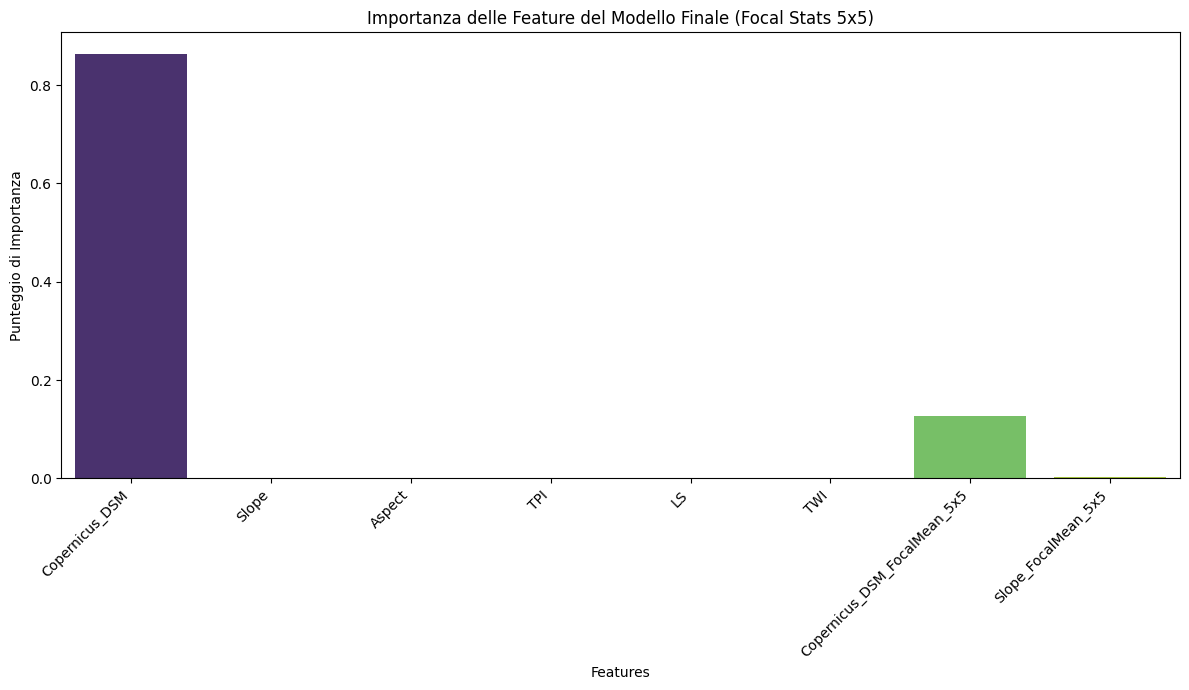

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for updated feature importances (from the final model with 5x5 focal stats)
fig = plt.figure(figsize=(12, 7))
sns.barplot(x=feature_importances_updated.index, y=feature_importances_updated.values, palette='viridis')
plt.title('Importanza delle Feature del Modello Finale (Focal Stats 5x5)')
plt.xlabel('Features')
plt.ylabel('Punteggio di Importanza')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


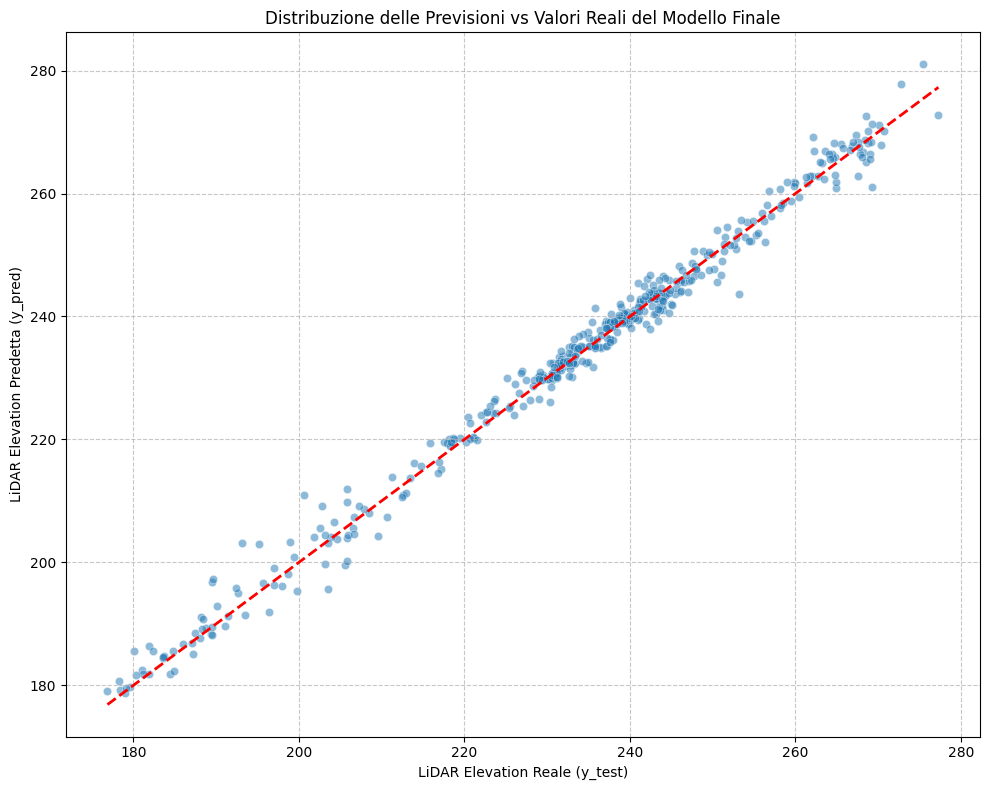

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(10, 8))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Linea di perfetta previsione
plt.title('Distribuzione delle Previsioni vs Valori Reali del Modello Finale')
plt.xlabel('LiDAR Elevation Reale (y_test)')
plt.ylabel('LiDAR Elevation Predetta (y_pred)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [29]:
# Calcolo dell'errore residuo
residuals = y_test - y_pred

print("Primi 5 valori dell'errore residuo:")
display(residuals[:5]) # Visualizza i primi 5 elementi di un array NumPy

print("\nStatistiche descrittive dell'errore residuo:")
display(pd.Series(residuals).describe()) # Converti in Series per usare .describe()

Primi 5 valori dell'errore residuo:


array([-0.3249852 ,  0.91409393, -2.16507599, -1.15941727,  1.33326523])


Statistiche descrittive dell'errore residuo:


,0
count,447.000000
mean,-0.311423
std,2.298887
min,-10.297939
25%,-1.413830
50%,-0.397914
75%,0.923062
max,9.504800


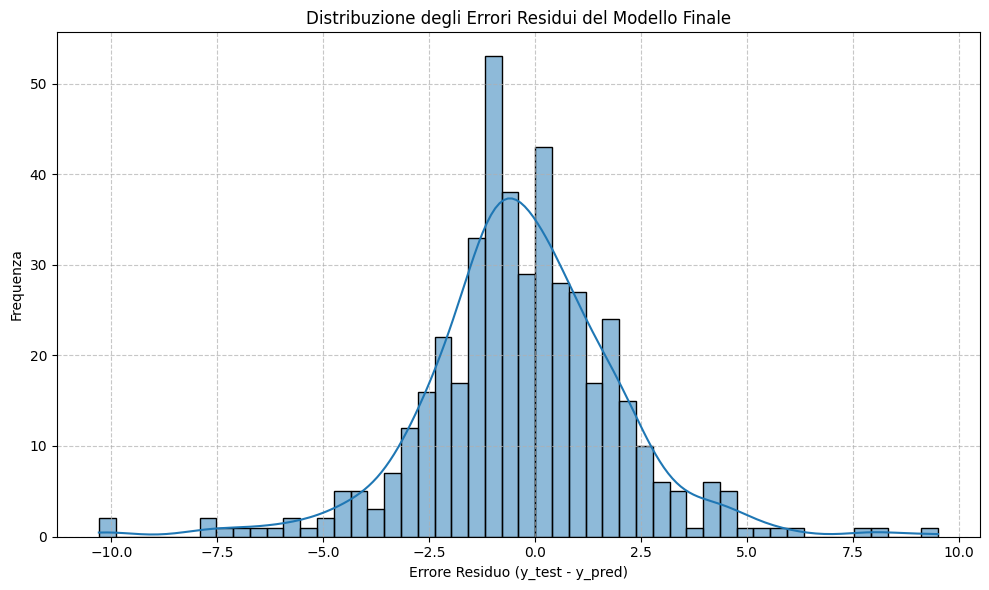

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(10, 6))
sns.histplot(residuals, bins=50, kde=True)
plt.title('Distribuzione degli Errori Residui del Modello Finale')
plt.xlabel('Errore Residuo (y_test - y_pred)')
plt.ylabel('Frequenza')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


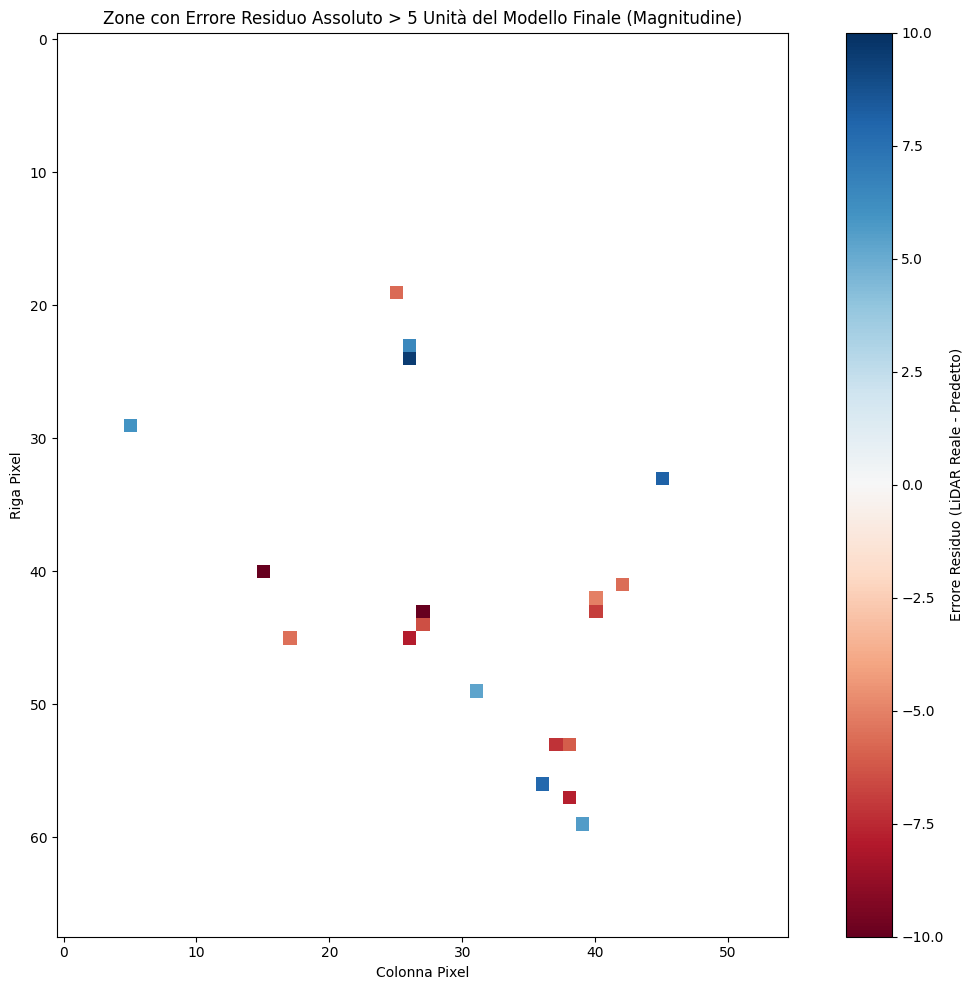

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Make predictions on the entire valid dataset (X_features)
y_pred_full = rf_model.predict(X_features)

# Calculate residuals for the entire valid dataset
full_residuals = y_target - y_pred_full

# Create an empty 2D array to store the residuals, same shape as original raster
# Initialize with NaN to represent areas outside the final_valid_mask
residuals_2d = np.full(lidar_data.shape, np.nan)

# Fill the 2D array with residuals for the valid pixels
# final_valid_mask is a 2D boolean array of the same shape as lidar_data
residuals_2d[final_valid_mask] = full_residuals

# Identify areas where absolute residual error exceeds 5 units
large_error_zones = np.copy(residuals_2d)
large_error_zones[np.abs(residuals_2d) <= 5] = np.nan # Set values <= 5 (abs) to NaN to highlight only large errors

# Visualize these zones showing the magnitude of the large residuals
fig = plt.figure(figsize=(12, 10))
plt.imshow(large_error_zones, cmap='RdBu', origin='upper', vmin=-10, vmax=10) # Using a divergent colormap centered at 0
plt.colorbar(label='Errore Residuo (LiDAR Reale - Predetto)')
plt.title('Zone con Errore Residuo Assoluto > 5 Unità del Modello Finale (Magnitudine)')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()
plt.show()

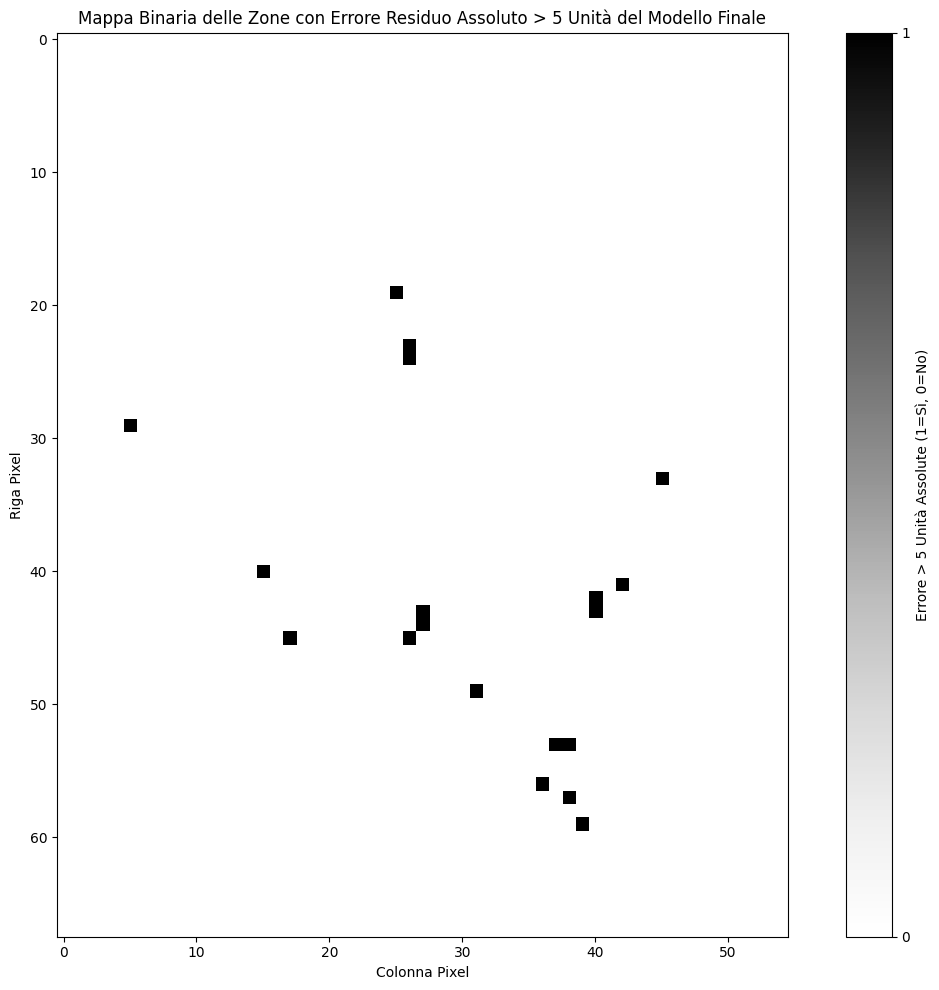

In [9]:
# Create a binary map: 1 where absolute error > 5, 0 where absolute error <= 5, NaN elsewhere
binary_large_error_map = np.full(lidar_data.shape, np.nan)
# Only consider valid pixels from final_valid_mask
binary_large_error_map[final_valid_mask] = (np.abs(full_residuals) > 5).astype(float)

fig = plt.figure(figsize=(12, 10))
# Use a grayscale colormap for binary visualization. cmap='Greys' or 'binary'
plt.imshow(binary_large_error_map, cmap='Greys', origin='upper', vmin=0, vmax=1)
plt.colorbar(ticks=[0, 1], label='Errore > 5 Unità Assolute (1=Sì, 0=No)')
plt.title('Mappa Binaria delle Zone con Errore Residuo Assoluto > 5 Unità del Modello Finale')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()
plt.show()

### Analisi dell'Autocorrelazione Spaziale dei Residui con Moran's I

Per quantificare e verificare statisticamente la presenza di pattern spaziali nei residui, calcoleremo l'indice di Moran's I. Questo indice varia generalmente tra -1 (dispersione perfetta) e +1 (clusterizzazione perfetta), con 0 che indica una distribuzione spaziale casuale. Un valore positivo significativo suggerisce che i valori simili dei residui sono raggruppati spazialmente.

In [66]:
import pysal.lib as ps
import esda # Importa direttamente esda
import numpy as np

# Otteniamo le dimensioni della griglia dal lidar_data
nrows, ncols = lidar_data.shape

# Costruiamo una matrice dei pesi spaziali di tipo Rook contiguity per l'intera griglia
# lat2W crea una matrice W dove ogni osservazione è un pixel della griglia (0 a nrows*ncols - 1)
w_full_grid = ps.weights.lat2W(nrows=nrows, ncols=ncols, rook=True)

# Identifichiamo gli indici dei pixel validi nell'array 1D linearizzato (nella griglia completa).
# Questi indici sono le "old_ids" che vogliamo mappare ai "new_ids" per full_residuals.
valid_original_1d_indices = np.where(final_valid_mask.flatten())[0]

# Creiamo un mapping dagli ID originali (nella griglia completa) ai nuovi ID (nell'array full_residuals)
old_to_new_id_map = {old_id: new_id for new_id, old_id in enumerate(valid_original_1d_indices)}

# Costruiamo un nuovo dizionario di vicini per i soli pixel validi
new_neighbors = {}
for new_id, old_id in enumerate(valid_original_1d_indices):
    # Otteniamo i vicini dell'old_id dalla matrice dei pesi della griglia completa
    # Se old_id non ha vicini (e.g., ai bordi della griglia), neighbors_of_old_id sarà vuoto
    neighbors_of_old_id = w_full_grid.neighbors.get(old_id, [])

    # Filtriamo i vicini per includere solo quelli che sono anche pixel validi
    valid_neighbors_new_ids = [
        old_to_new_id_map[neighbor_old_id]
        for neighbor_old_id in neighbors_of_old_id
        if neighbor_old_id in old_to_new_id_map # Verifica se il vicino è un pixel valido
    ]
    new_neighbors[new_id] = valid_neighbors_new_ids

# Creiamo il nuovo oggetto weights 'w' usando il dizionario new_neighbors
# Dobbiamo assicurarci che non ci siano osservazioni senza vicini se zero_policy è 'drop'.
# PySAL W constructor allows to specify IDs. Qui, gli ID sono da 0 a len(full_residuals)-1.
w = ps.weights.W(new_neighbors)

# Calcoliamo l'indice di Moran's I
moran = esda.Moran(full_residuals, w)

print(f"Moran's I (Residui): {moran.I:.4f}")
print(f"Valore p simulato (Moran's I): {moran.p_sim:.4f}")

print("\nInterpretazione:")
if moran.p_sim < 0.05:
    if moran.I > 0:
        print("C'è una significativa autocorrelazione spaziale positiva (i residui sono raggruppati spazialmente).")
    else:
        print("C'è una significativa autocorrelazione spaziale negativa (i residui sono dispersi spazialmente).")
else:
    print("Non c'è una significativa autocorrelazione spaziale (i residui sono distribuiti casualmente).")

Moran's I (Residui): 0.3683
Valore p simulato (Moran's I): 0.0010

Interpretazione:
C'è una significativa autocorrelazione spaziale positiva (i residui sono raggruppati spazialmente).


### Analisi Dettagliata delle Caratteristiche Topografiche nelle Zone ad Alto Errore

Per capire meglio le condizioni del terreno dove il modello ha le maggiori difficoltà, confronteremo le distribuzioni delle caratteristiche topografiche (come `Copernicus_DSM`, `Slope`, `LS`, `TWI`, ecc.) all'interno delle zone ad alto errore (già identificate) con la distribuzione di queste stesse caratteristiche sull'intero dataset valido. Questo ci aiuterà a identificare se ci sono range specifici o combinazioni di valori che sono problematici per il modello.

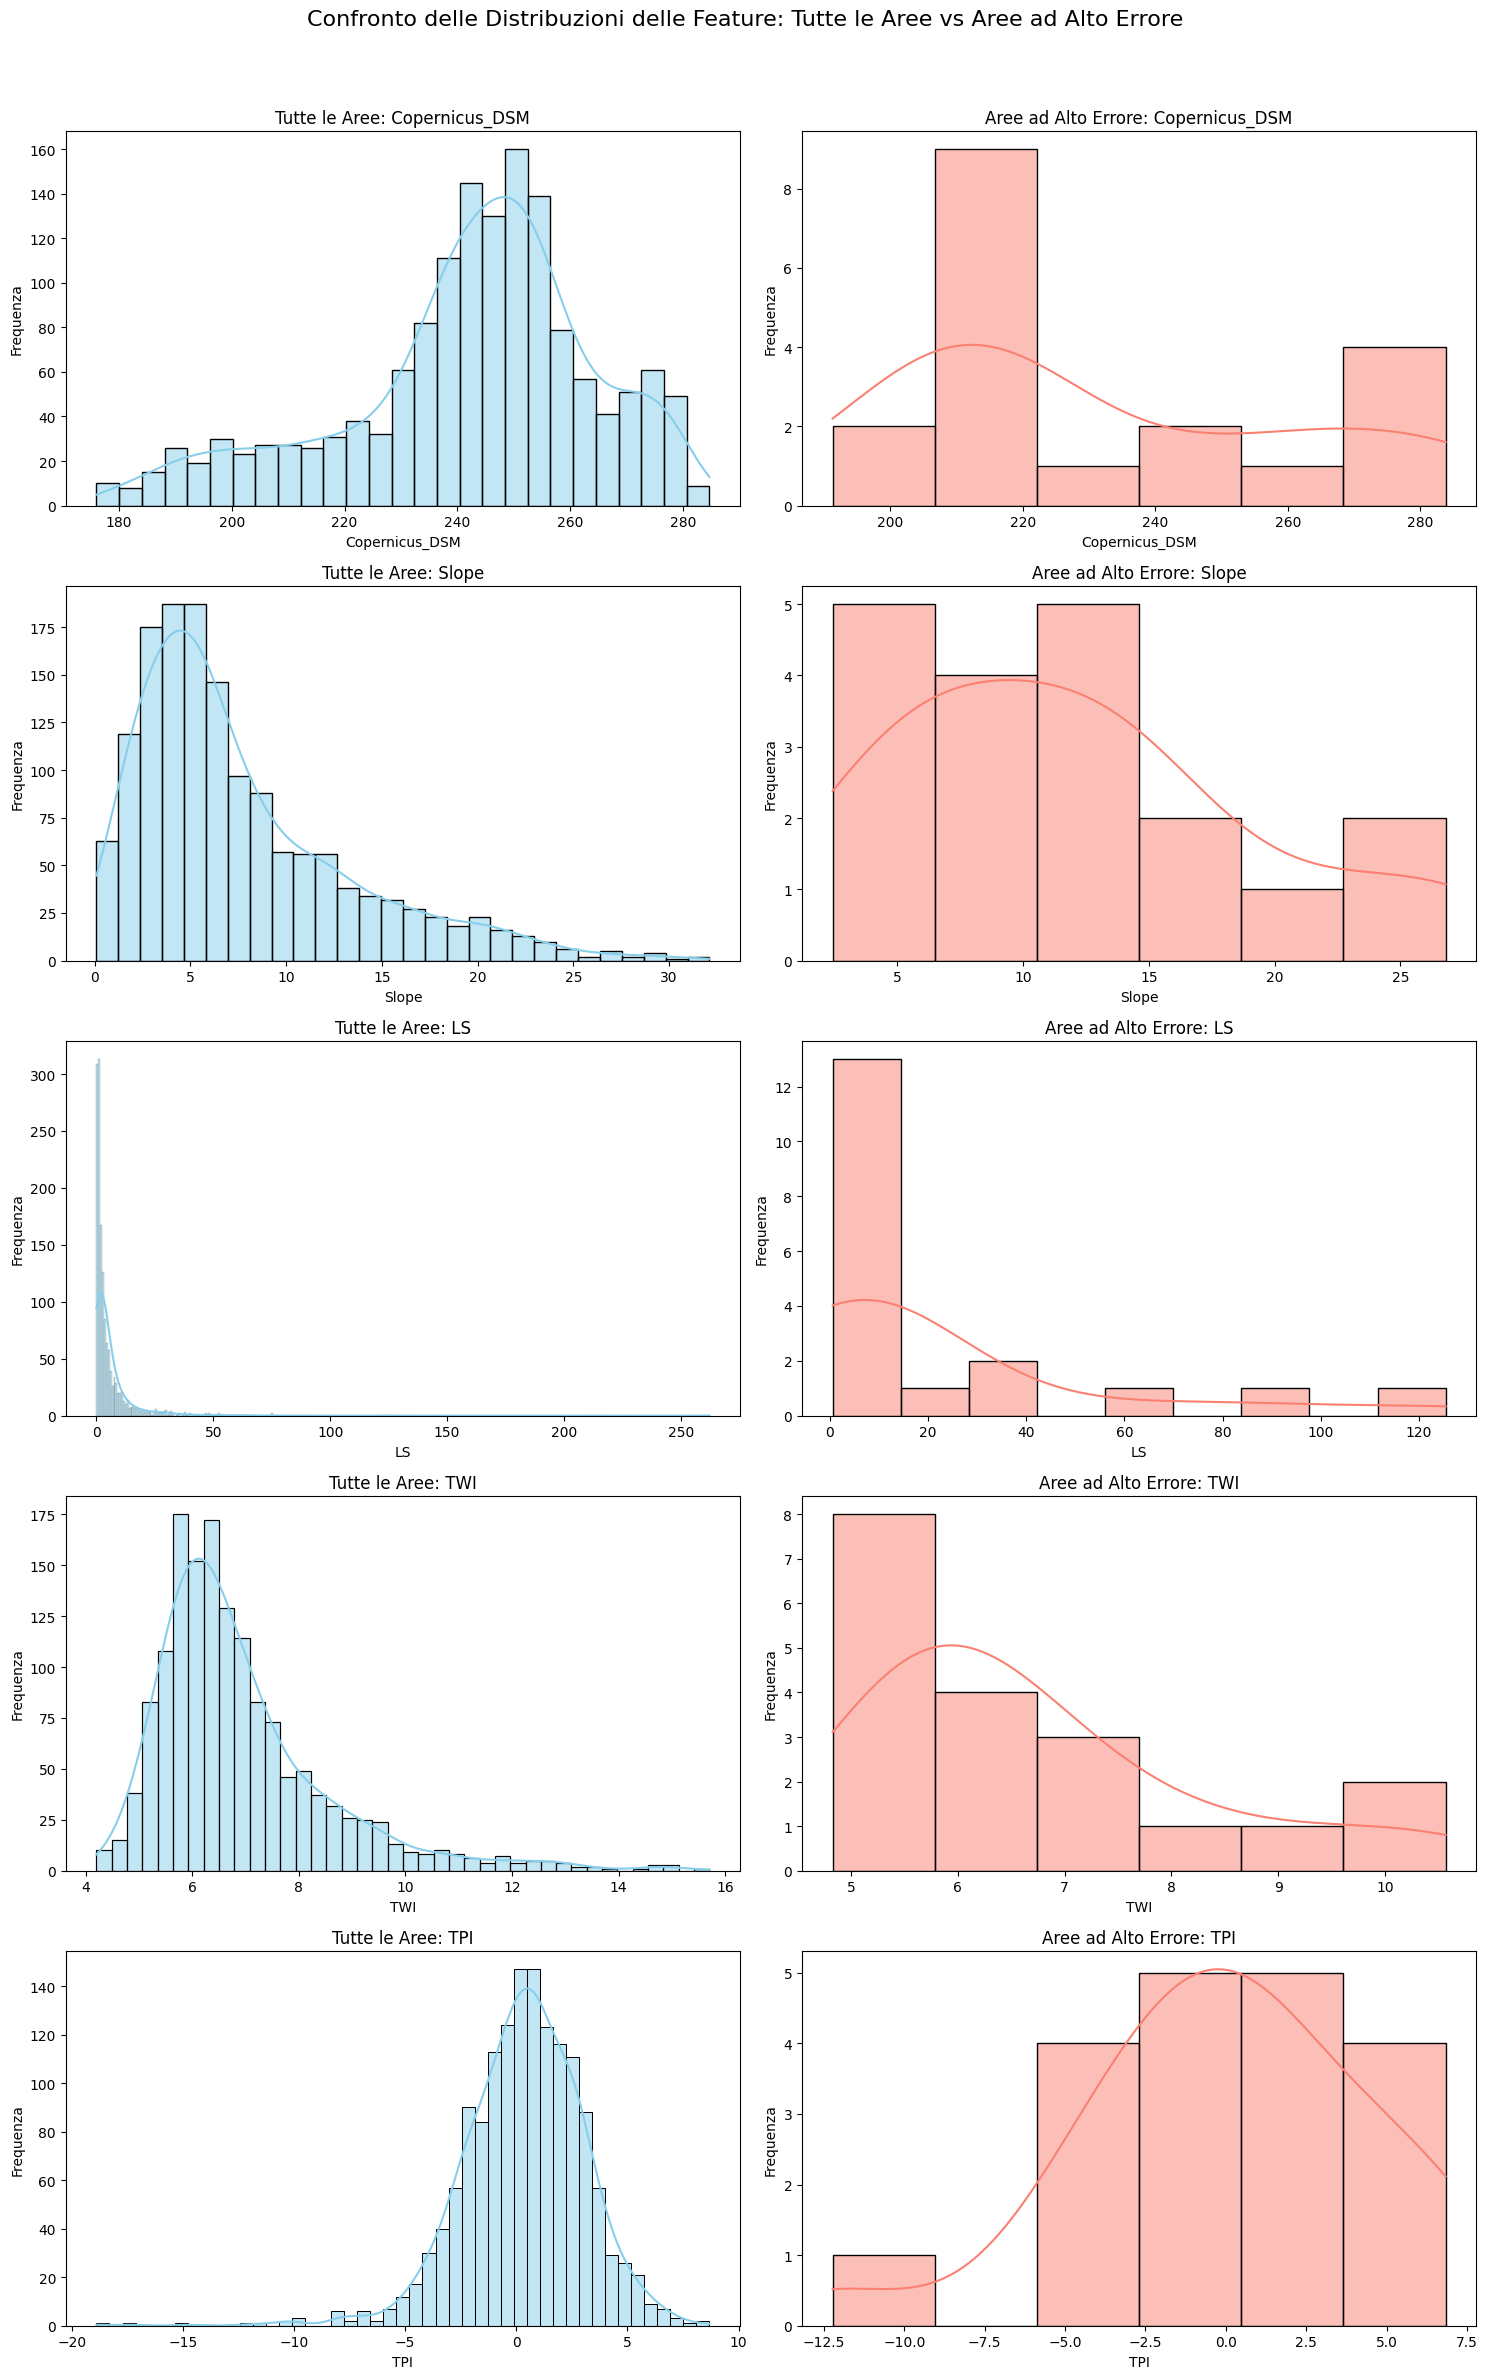

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assicurati che feature_names sia disponibile (già definito in 04269d0a)
# feature_names = [
#     'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
#     'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5'
# ]

# Crea un DataFrame per tutte le feature valide per un confronto più semplice
df_all_features = pd.DataFrame(X_features, columns=feature_names)

# Seleziona un sottoinsieme di feature chiave da confrontare
key_features_to_compare = [
    'Copernicus_DSM',
    'Slope',
    'LS',
    'TWI',
    'TPI'
]

# Configura i subplot per visualizzare le distribuzioni
fig, axes = plt.subplots(len(key_features_to_compare), 2, figsize=(15, 5 * len(key_features_to_compare)))
fig.suptitle('Confronto delle Distribuzioni delle Feature: Tutte le Aree vs Aree ad Alto Errore', fontsize=16)

for i, feature in enumerate(key_features_to_compare):
    # Distribuzione per tutte le aree valide
    sns.histplot(df_all_features[feature], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Tutte le Aree: {feature}')
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel('Frequenza')

    # Distribuzione per le aree ad alto errore
    sns.histplot(df_high_error[feature], kde=True, ax=axes[i, 1], color='salmon')
    axes[i, 1].set_title(f'Aree ad Alto Errore: {feature}')
    axes[i, 1].set_xlabel(feature)
    axes[i, 1].set_ylabel('Frequenza')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Regola il layout per il titolo principale
plt.show()

### Analisi dell'Ampiezza dell'Errore in relazione alle Feature Topografiche

Per approfondire, visualizziamo la relazione tra l'ampiezza dell'errore residuo assoluto e i valori delle singole feature topografiche per tutti i pixel validi. Questo può rivelare se errori maggiori si verificano in specifici range di valori delle feature.

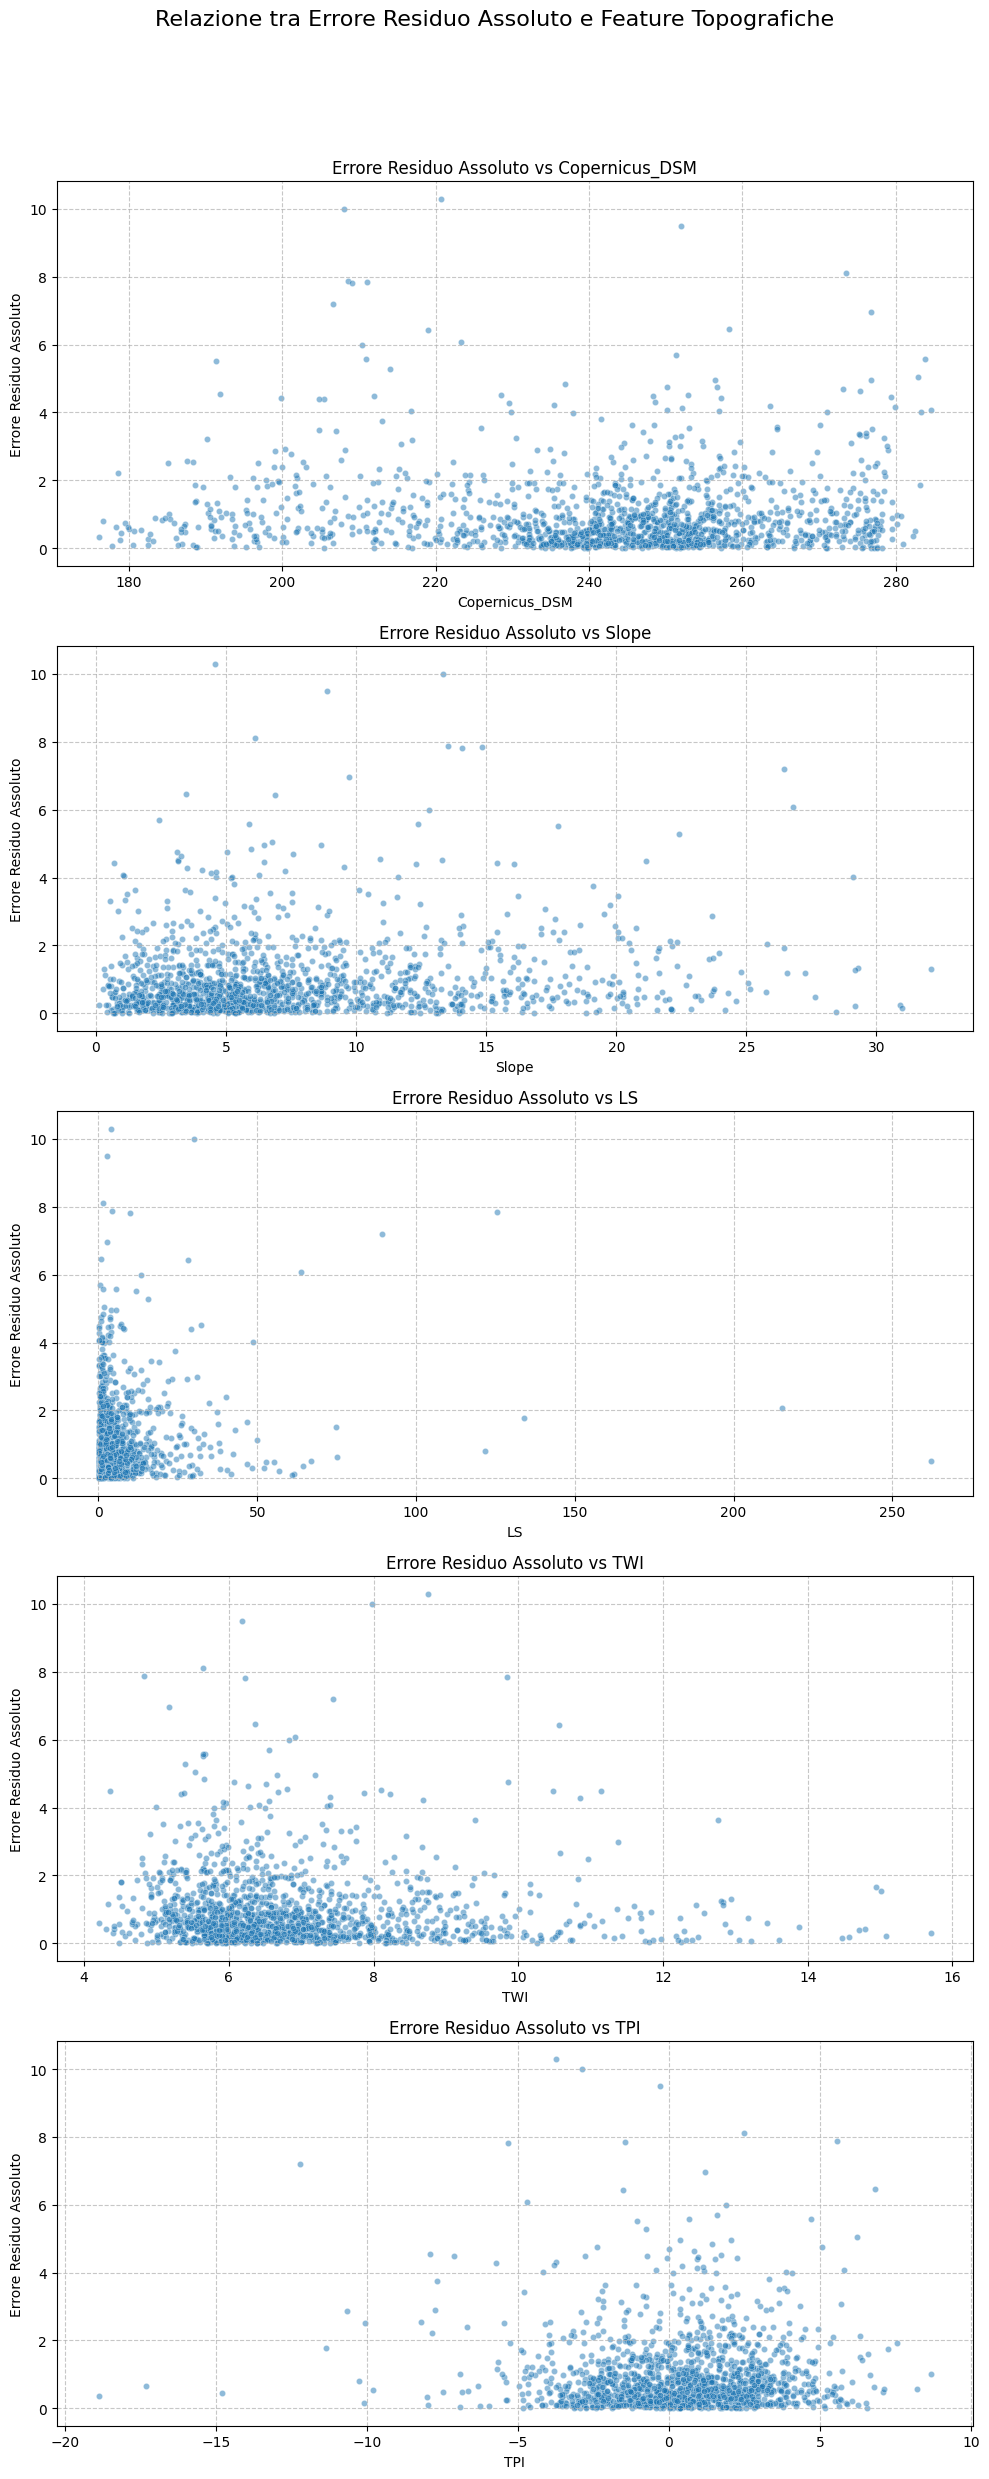

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcola l'errore residuo assoluto per tutti i pixel validi
abs_full_residuals = np.abs(full_residuals)

# Aggiungi l'errore residuo assoluto al DataFrame delle feature per facilitare il plotting
df_all_features['Absolute_Residual_Error'] = abs_full_residuals

fig, axes = plt.subplots(len(key_features_to_compare), 1, figsize=(10, 5 * len(key_features_to_compare)))
fig.suptitle('Relazione tra Errore Residuo Assoluto e Feature Topografiche', fontsize=16, y=1.02)

for i, feature in enumerate(key_features_to_compare):
    sns.scatterplot(x=feature, y='Absolute_Residual_Error', data=df_all_features, ax=axes[i], alpha=0.5, s=20)
    axes[i].set_title(f'Errore Residuo Assoluto vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Errore Residuo Assoluto')
    axes[i].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Regola il layout per il titolo principale
plt.show()

Mediana della pendenza utilizzata per la categorizzazione: 5.91


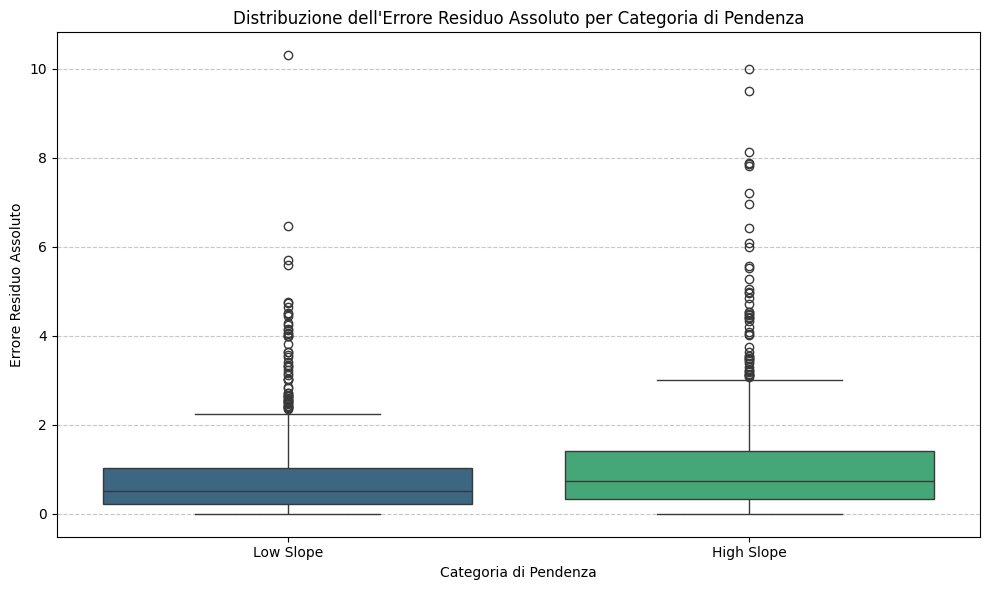

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definisci una soglia per dividere le pendenze in 'basse' e 'alte'
# Per esempio, usiamo la mediana della pendenza come soglia
median_slope = df_all_features['Slope'].median()
print(f"Mediana della pendenza utilizzata per la categorizzazione: {median_slope:.2f}")

# Crea una nuova colonna per la categoria di pendenza
df_all_features['Slope_Category'] = df_all_features['Slope'].apply(lambda x: 'High Slope' if x > median_slope else 'Low Slope')

# Crea un boxplot per confrontare la distribuzione dell'errore assoluto residuo tra le categorie di pendenza
fig = plt.figure(figsize=(10, 6))
sns.boxplot(x='Slope_Category', y='Absolute_Residual_Error', data=df_all_features, palette='viridis', hue='Slope_Category', legend=False)
plt.title('Distribuzione dell\'Errore Residuo Assoluto per Categoria di Pendenza')
plt.xlabel('Categoria di Pendenza')
plt.ylabel('Errore Residuo Assoluto')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

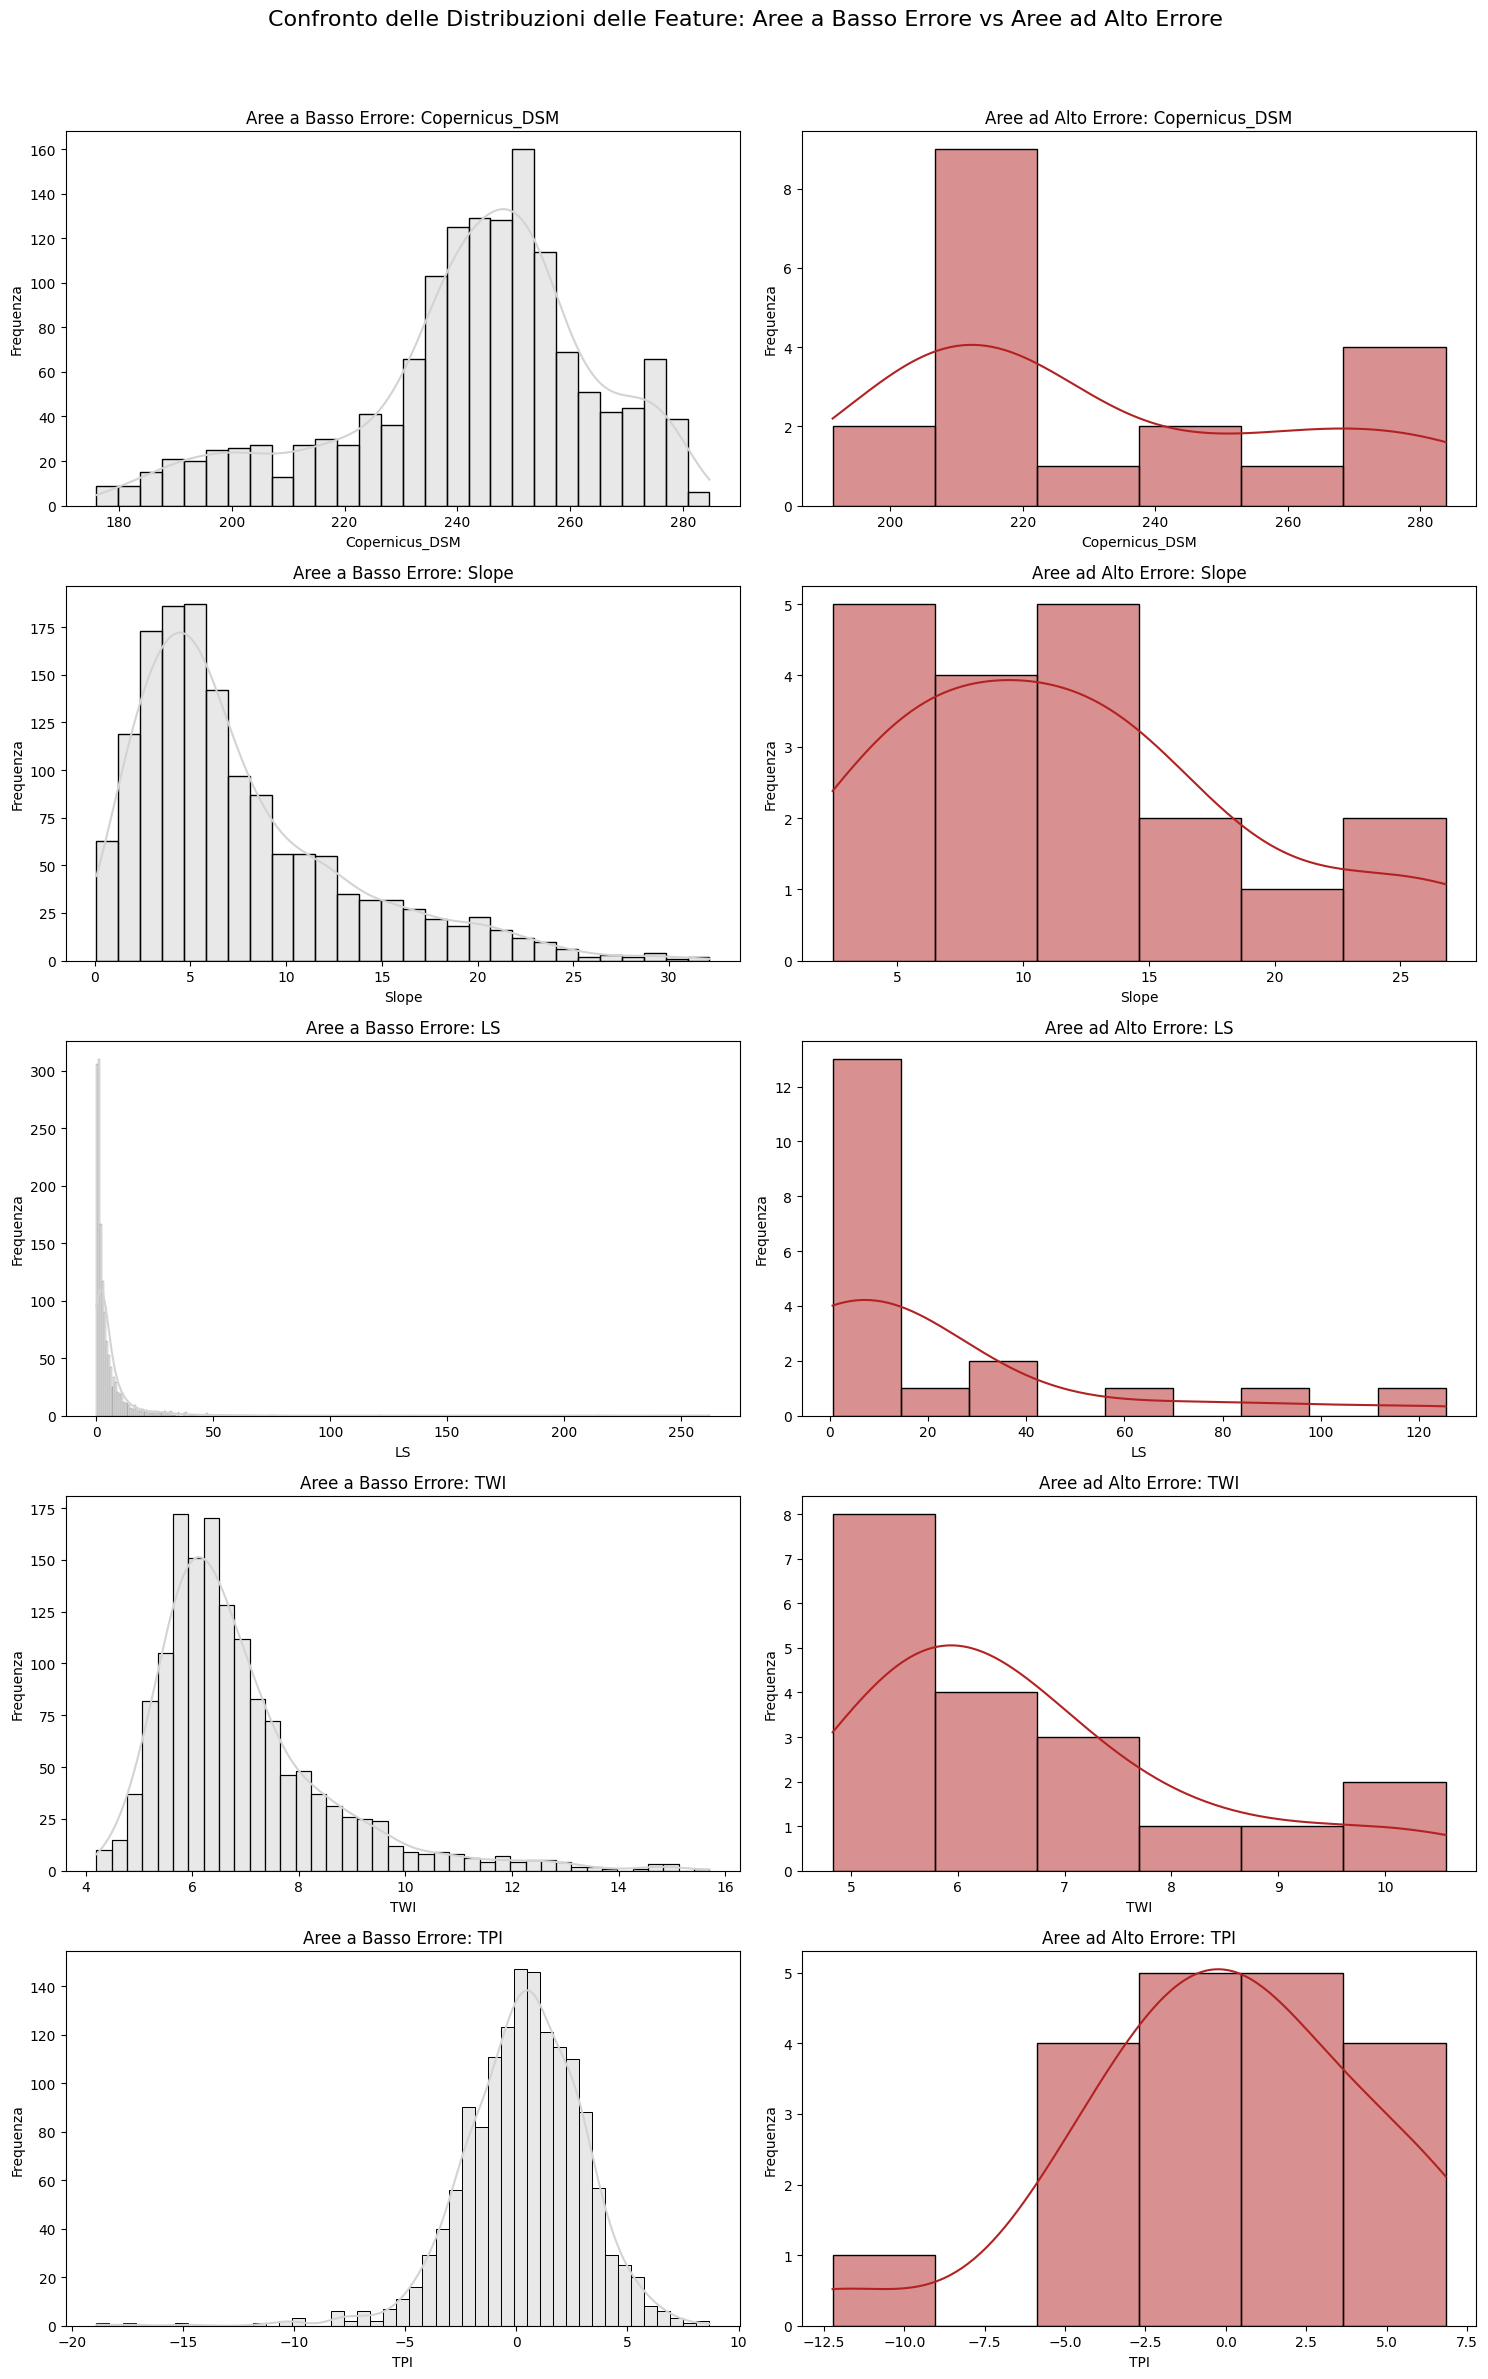

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np # Make sure numpy is imported for np.abs

# Nomi delle feature (assicurati che siano gli stessi usati per X_features)
feature_names = [
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5'
]

# Crea un DataFrame per tutte le feature valide per un confronto più semplice
df_all_features = pd.DataFrame(X_features, columns=feature_names)

# Calcola l'errore residuo assoluto per tutti i pixel validi
# `full_residuals` should be available from previous cells.
abs_full_residuals = np.abs(full_residuals)

# Aggiungi l'errore residuo assoluto al DataFrame delle feature per facilitare il plotting
df_all_features['Absolute_Residual_Error'] = abs_full_residuals

# Definisci la soglia per l'errore assoluto (es. 5 unità come usato precedentemente)
high_error_threshold = 5

# Definisci le aree a basso errore (Absolute_Residual_Error <= 5)
df_low_error = df_all_features[df_all_features['Absolute_Residual_Error'] <= high_error_threshold]

# Definisci le aree ad alto errore (Absolute_Residual_Error > 5)
df_high_error = df_all_features[df_all_features['Absolute_Residual_Error'] > high_error_threshold]

# Seleziona le stesse feature chiave da confrontare (dalla cella 778eeeb7)
key_features_to_compare = [
    'Copernicus_DSM',
    'Slope',
    'LS',
    'TWI',
    'TPI'
]

# Configura i subplot per visualizzare le distribuzioni
fig, axes = plt.subplots(len(key_features_to_compare), 2, figsize=(15, 5 * len(key_features_to_compare)))
fig.suptitle('Confronto delle Distribuzioni delle Feature: Aree a Basso Errore vs Aree ad Alto Errore', fontsize=16)

for i, feature in enumerate(key_features_to_compare):
    # Distribuzione per le aree a basso errore
    sns.histplot(df_low_error[feature], kde=True, ax=axes[i, 0], color='lightgray', label='Basso Errore')
    axes[i, 0].set_title(f'Aree a Basso Errore: {feature}')
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel('Frequenza')

    # Distribuzione per le aree ad alto errore
    sns.histplot(df_high_error[feature], kde=True, ax=axes[i, 1], color='firebrick', label='Alto Errore')
    axes[i, 1].set_title(f'Aree ad Alto Errore: {feature}')
    axes[i, 1].set_xlabel(feature)
    axes[i, 1].set_ylabel('Frequenza')

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Regola il layout per il titolo principale
plt.show()

### Mappa Spaziale degli Errori Residui

Questa mappa visualizza la distribuzione spaziale degli errori residui (`y_reale - y_predetto`). I colori blu scuro indicano aree dove il modello ha sovrastimato l'elevazione, mentre i colori rosso scuro indicano aree dove il modello ha sottostimato l'elevazione. Questo può aiutare a identificare cluster geografici di errore, suggerendo che il modello potrebbe avere difficoltà in particolari tipi di terreno o condizioni ambientali.

### Esportazione delle Coordinate dei Cluster di Errore Elevato

Il seguente codice identifica i pixel dove l'errore residuo assoluto supera una soglia definita (5 unità) e ne esporta le coordinate geografiche (X, Y) e il valore dell'errore residuo in un file CSV. Questo file può essere utilizzato per analisi spaziali più dettagliate o per la pianificazione di ulteriori indagini.

In [22]:
import pandas as pd
import numpy as np
import rasterio

# Definisci la soglia per l'errore assoluto (es. 5 unità come usato precedentemente)
high_error_threshold = 5

# Identifica le posizioni (righe, colonne) nella mappa 2D dei residui
# dove l'errore assoluto supera la soglia e non è NaN (cioè, sono pixel validi)
rows_high_error, cols_high_error = np.where(
    (~np.isnan(residuals_2d)) & (np.abs(residuals_2d) > high_error_threshold)
)

# Ottieni il valore del residuo per queste posizioni
residuals_values_high_error = residuals_2d[rows_high_error, cols_high_error]

# Carica il trasform affine dal file LiDAR_path per la conversione delle coordinate
with rasterio.open(LiDAR_path) as src:
    lidar_transform = src.transform

# Converti gli indici di riga e colonna in coordinate geografiche (x, y)
x_coords, y_coords = rasterio.transform.xy(lidar_transform, rows_high_error, cols_high_error)

# Crea un DataFrame con le coordinate e i residui
df_error_clusters = pd.DataFrame({
    'x_coordinate': x_coords,
    'y_coordinate': y_coords,
    'residual_error': residuals_values_high_error
})

# Definisci il percorso del file CSV di output
output_csv_path = '/content/high_error_clusters_coordinates.csv'

# Salva il DataFrame in un file CSV
df_error_clusters.to_csv(output_csv_path, index=False)

print(f"Coordinate dei cluster di errore elevato salvate in: {output_csv_path}")
display(df_error_clusters.head())

Coordinate dei cluster di errore elevato salvate in: /content/high_error_clusters_coordinates.csv


,x_coordinate,y_coordinate,residual_error
0,244296.781044,1.889697e+06,-5.695853
1,244326.860406,1.889577e+06,6.456855
2,244326.860406,1.889547e+06,9.504800
3,243695.193788,1.889396e+06,5.985295
4,244898.368300,1.889276e+06,8.121097


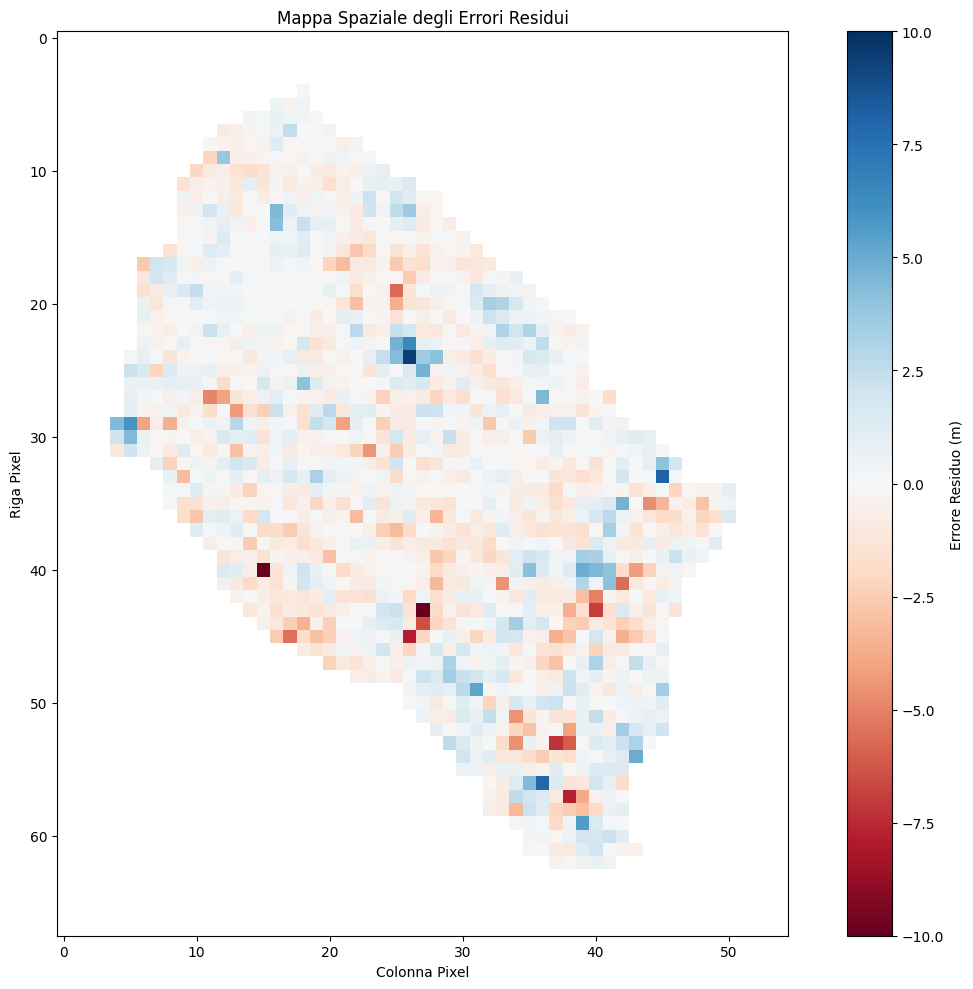

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# La variabile `residuals_2d` contiene già i residui mappati sulla griglia 2D
# e dovrebbe essere stata creata in una cella precedente (cella `fde1fb56`).
# Se non fosse disponibile, andrebbe ricalcolata.

fig = plt.figure(figsize=(12, 10))
plt.imshow(residuals_2d, cmap='RdBu', origin='upper', vmin=-10, vmax=10) # 'RdBu' è una colormap divergente per errori
plt.colorbar(label='Errore Residuo (m)')
plt.title('Mappa Spaziale degli Errori Residui')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()
plt.show()

In [27]:
import os

# List all files and directories in /content
content_items = os.listdir('/content')

# Sort the list for better readability
content_items.sort()

print("Contenuto della directory /content:")
for item in content_items:
    print(item)

Contenuto della directory /content:
.config
0_DSM_Copernicus_30m_mascherato.tif
1.LS_factor_DSM_Copernicus_Yaxha_30m_mascherato_depression_filled.tif
1.TWI_DSM_Copernicus_Yaxha_30m_mascherato_depression_filled.tif
1.aspect_DSM_Copernicus_Yaxha_30m_mascherato.tif
1.slope_DSM_Copernicus_Yaxha_30m_mascherato_gradi.tif
2.TPI_DSM_Copernicus_Yaxha_30m_mascherato_r90m.tif
DSM_Copernicus_no_laguna_bordi_depression_filled.tif
LS_factor_DSM_Copernicus_no_laguna_bordi_depression_filled.tif
LiDAR_elev_aggregated_30m.tif
LiDAR_prediction_map.tif
LiDAR_prediction_map_full_park.tif
TPI_DSM_Copernicus_no_laguna_bordi_r90m.tif
TWI_DSM_Copernicus_no_laguna_bordi_depression_filled.tif
aspect_DSM_Copernicus_no_laguna_bordi_no_flat.tif
download.png
drive
high_error_clusters_coordinates.csv
high_error_zones_statistics.csv
model_comparison_metrics.csv
priority_map_drone_flights.png
priority_map_drone_flights.tif
sample_data
slope_DSM_Copernicus_gradi_no_laguna_bordi.tif
spatial_block_map.tif
spatial_residual

### Esportazione della Mappa degli Errori Residui in GeoTIFF e Generazione del File QML

Esportiamo la mappa 2D degli errori residui come un file GeoTIFF. Questo renderà la mappa compatibile con software GIS come QGIS. Insieme al GeoTIFF, genereremo un file `.qml` (QGIS Layer Style File) che includerà la simbologia (`RdBu` divergent colormap con range da -10 a 10 metri), permettendo di caricare lo stile direttamente in QGIS senza doverlo configurare manualmente.

In [23]:
import rasterio
import numpy as np
import os

# Definisci il percorso del file di output GeoTIFF
output_residual_map_path = '/content/spatial_residual_error_map.tif'

# Carica il profilo (metadati) dal file LiDAR_path per la georeferenziazione
with rasterio.open(LiDAR_path) as src:
    profile_residual_map = src.profile

# Aggiorna il profilo per il nuovo GeoTIFF dei residui
profile_residual_map.update(
    dtype=np.float32, # I residui sono float
    count=1,
    nodata=np.nan, # Manteniamo NaN come nodata
    tiled=True,
    blockxsize=256,
    blockysize=256
)

# Scrivi il file GeoTIFF
with rasterio.open(output_residual_map_path, 'w', **profile_residual_map) as dst:
    dst.write(residuals_2d.astype(np.float32), 1)

print(f"Mappa spaziale degli errori residui esportata in: {output_residual_map_path}")

# --- Generazione del file QML (QGIS Layer Style File) ---

qml_filename = '/content/spatial_residual_error_map.qml'

qml_content = f"""<!DOCTYPE qgis PUBLIC 'http://mrcc.com/qgis.dtd' 'GISCode/libqgis_core.normal.desktop'>
<qgis version="3.28.11-Firenze" style_version="1.0">
  <rasterrenderer opacity="1" alphaBand="0" band="1" bandMapKey="" type="singlebandpseudocolor">
    <rastershader>
      <colorrampshader colorRampType="Diverging" clip="0">
        <item alpha="255" value="-10" label="-10 (Sovrastima Forte)" color="#2166AC"/>
        <item alpha="255" value="-5" label="-5" color="#67A9CF"/>
        <item alpha="255" value="0" label="0 (Nessun Errore)" color="#F7F7F7"/>
        <item alpha="255" value="5" label="5" color="#EF8A62"/>
        <item alpha="255" value="10" label="10 (Sottostima Forte)" color="#B2182B"/>
      </colorrampshader>
    </rastershader>
  </rasterrenderer>
</qgis>"""

with open(qml_filename, 'w') as f:
    f.write(qml_content)

print(f"File QML generato in: {qml_filename}")


Mappa spaziale degli errori residui esportata in: /content/spatial_residual_error_map.tif
File QML generato in: /content/spatial_residual_error_map.qml


### Mappa di Priorità per il Sorvolo con i Droni (Basata su Errore Residuo Elevato)

Questa mappa visualizza le aree (in nero) dove l'errore residuo assoluto del modello supera le 5 unità. Queste zone sono considerate a più alta priorità per un'indagine più approfondita, come ad esempio il sorvolo con droni, per comprendere le discrepanze o raccogliere dati aggiuntivi.

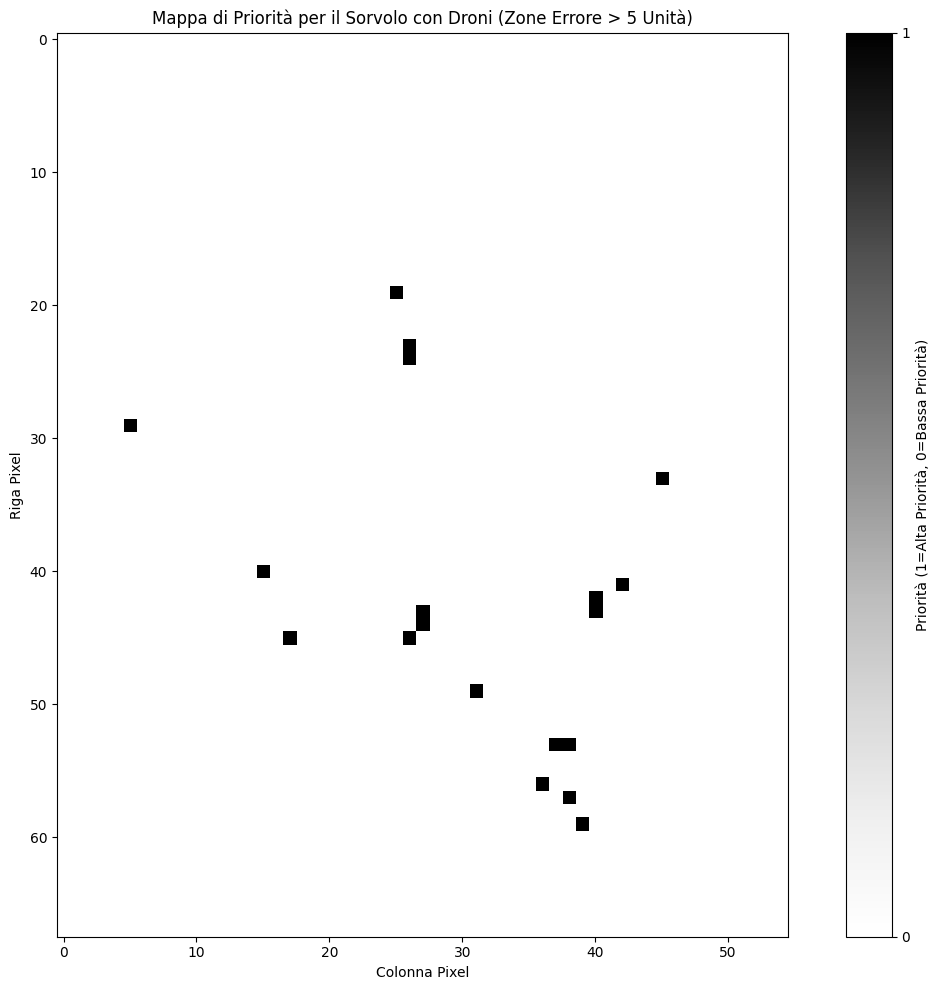

Mappa di priorità salvata come immagine PNG in: /content/priority_map_drone_flights.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# La binary_large_error_map è stata generata nella cella 1cad142f
# Assicuriamoci che sia disponibile e aggiornata

fig = plt.figure(figsize=(12, 10))
plt.imshow(binary_large_error_map, cmap='Greys', origin='upper', vmin=0, vmax=1)
plt.colorbar(ticks=[0, 1], label='Priorità (1=Alta Priorità, 0=Bassa Priorità)')
plt.title('Mappa di Priorità per il Sorvolo con Droni (Zone Errore > 5 Unità)')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()

# Salva la mappa come immagine PNG
output_image_path = '/content/priority_map_drone_flights.png'
plt.savefig(output_image_path, dpi=300)
plt.show()

print(f"Mappa di priorità salvata come immagine PNG in: {output_image_path}")

In [11]:
import rasterio
import numpy as np

# Carica i metadati dal file LiDAR originale
with rasterio.open(LiDAR_path) as src:
    profile_priority_map = src.profile

# Aggiorna il profilo per il nuovo file GeoTIFF
# Assicurati che il tipo di dato sia float32 per gestire i NaN
profile_priority_map.update(
    dtype=np.float32, # binary_large_error_map può contenere NaN
    count=1,
    nodata=np.nan, # I NaN verranno scritti come valori NoData nel GeoTIFF
    tiled=True,
    blockxsize=256,
    blockysize=256
)

# Definisci il percorso del file di output GeoTIFF
output_geotiff_path = '/content/priority_map_drone_flights.tif'

# Scrivi il nuovo file GeoTIFF
with rasterio.open(output_geotiff_path, 'w', **profile_priority_map) as dst:
    dst.write(binary_large_error_map.astype(np.float32), 1) # Assicurati che il tipo di dato sia float32

print(f"Mappa di priorità esportata come GeoTIFF in: {output_geotiff_path}")

Mappa di priorità esportata come GeoTIFF in: /content/priority_map_drone_flights.tif


### Applicazione del Modello all'Intera Area del Parco (El Triangulo Cultural)

Ora che abbiamo il modello Random Forest addestrato e le mappe di priorità, applicheremo il modello all'intera estensione del parco El Triangulo Cultural, utilizzando le nuove feature raster fornite.

In [12]:
# Define file paths for the full park area (El Triangulo Cultural)
full_park_Copernicus_DSM_path = '/content/DSM_Copernicus_no_laguna_bordi_depression_filled.tif'
full_park_Slope_path = '/content/slope_DSM_Copernicus_gradi_no_laguna_bordi.tif'
full_park_Aspect_path = '/content/aspect_DSM_Copernicus_no_laguna_bordi_no_flat.tif'
full_park_TPI_path = '/content/TPI_DSM_Copernicus_no_laguna_bordi_r90m.tif'
full_park_LS_path = '/content/LS_factor_DSM_Copernicus_no_laguna_bordi_depression_filled.tif'
full_park_TWI_path = '/content/TWI_DSM_Copernicus_no_laguna_bordi_depression_filled.tif'

# Load all new raster data for the full park area
copernicus_dsm_full_park, full_park_transform, _ = load_raster_data(full_park_Copernicus_DSM_path)
slope_full_park, _, _ = load_raster_data(full_park_Slope_path)
aspect_full_park, _, _ = load_raster_data(full_park_Aspect_path)
tpi_full_park, _, _ = load_raster_data(full_park_TPI_path)
ls_full_park, _, _ = load_raster_data(full_park_LS_path)
twi_full_park, _, _ = load_raster_data(full_park_TWI_path)

print("Dati raster per l'intero parco caricati con successo.")

Dati raster per l'intero parco caricati con successo.


In [13]:
# Calculate focal mean for the new Copernicus DSM and Slope with a 5x5 window
copernicus_dsm_focal_mean_full_park = calculate_focal_mean(copernicus_dsm_full_park, size=5)
slope_focal_mean_full_park = calculate_focal_mean(slope_full_park, size=5)

print("Medie focali per l'intero parco calcolate.")

Medie focali per l'intero parco calcolate.


In [14]:
# Create a comprehensive mask for the full park area
full_park_valid_mask = (~np.isnan(copernicus_dsm_full_park) &
                        ~np.isnan(slope_full_park) &
                        ~np.isnan(aspect_full_park) &
                        ~np.isnan(tpi_full_park) &
                        ~np.isnan(ls_full_park) &
                        ~np.isnan(twi_full_park) &
                        ~np.isnan(copernicus_dsm_focal_mean_full_park) &
                        ~np.isnan(slope_focal_mean_full_park))

# Extract features for prediction
X_full_park_features = np.array([
    copernicus_dsm_full_park[full_park_valid_mask],
    slope_full_park[full_park_valid_mask],
    aspect_full_park[full_park_valid_mask],
    tpi_full_park[full_park_valid_mask],
    ls_full_park[full_park_valid_mask],
    twi_full_park[full_park_valid_mask],
    copernicus_dsm_focal_mean_full_park[full_park_valid_mask],
    slope_focal_mean_full_park[full_park_valid_mask]
]).T

print(f"Shape delle feature per l'intero parco: {X_full_park_features.shape}")

Shape delle feature per l'intero parco: (255267, 8)


In [15]:
# Make predictions on the full park data
print("Generazione delle previsioni per l'intero parco...")
y_pred_full_park = rf_model.predict(X_full_park_features)
print("Previsioni generate.")

Generazione delle previsioni per l'intero parco...
Previsioni generate.


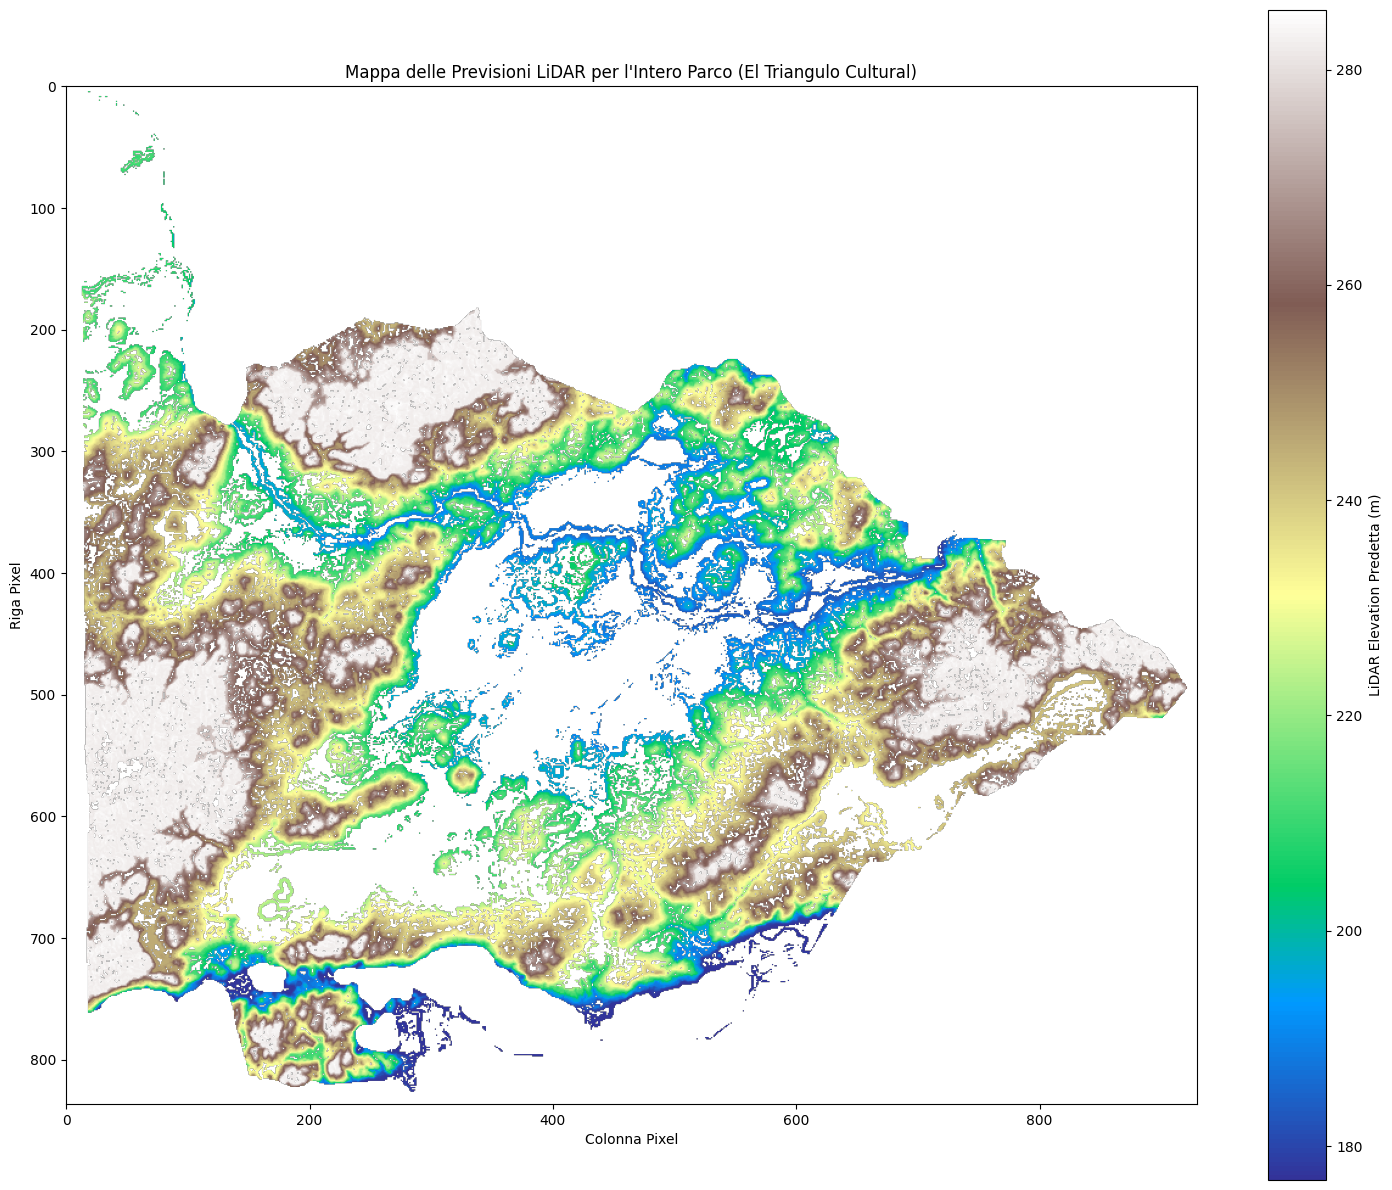

In [16]:
# Reconstruct the 2D prediction map for the full park
predicted_full_park_2d_map = np.full(copernicus_dsm_full_park.shape, np.nan, dtype=np.float32)
predicted_full_park_2d_map[full_park_valid_mask] = y_pred_full_park

# Visualize the full park prediction map
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(15, 12))
plt.imshow(predicted_full_park_2d_map, cmap='terrain', origin='upper')
plt.colorbar(label='LiDAR Elevation Predetta (m)')
plt.title('Mappa delle Previsioni LiDAR per l\'Intero Parco (El Triangulo Cultural)')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()
plt.show()

In [18]:
# Save the full park prediction map as a GeoTIFF

# Open the full park Copernicus DSM to get full profile
with rasterio.open(full_park_Copernicus_DSM_path) as src:
    profile_full_park_prediction = src.profile


profile_full_park_prediction.update(
    dtype=predicted_full_park_2d_map.dtype,
    count=1,
    nodata=np.nan, # Ensure NaNs are written as nodata in the GeoTIFF
    tiled=True,
    blockxsize=256,
    blockysize=256
)

# Define the output path for the full park prediction
output_full_park_prediction_path = '/content/LiDAR_prediction_map_full_park.tif'

# Write the new GeoTIFF
with rasterio.open(output_full_park_prediction_path, 'w', **profile_full_park_prediction) as dst:
    dst.write(predicted_full_park_2d_map, 1)

print(f"Mappa delle previsioni per l'intero parco esportata con successo in: {output_full_park_prediction_path}")

Mappa delle previsioni per l'intero parco esportata con successo in: /content/LiDAR_prediction_map_full_park.tif


### Confronto dell'Importanza delle Feature tra Modelli con Finestra Focale 3x3 e 5x5

In [19]:
import rasterio
import numpy as np
import pandas as pd

# Load the prediction map for the full park
prediction_map_path = '/content/LiDAR_prediction_map_full_park.tif'

with rasterio.open(prediction_map_path) as src:
    prediction_data = src.read(1)

# Flatten the array and remove NaN values for statistics
valid_predictions = prediction_data[~np.isnan(prediction_data)]

# Calculate descriptive statistics
descriptive_stats = pd.Series(valid_predictions).describe()

print("Statistiche Descrittive per LiDAR_prediction_map_full_park.tif:")
display(descriptive_stats)

Statistiche Descrittive per LiDAR_prediction_map_full_park.tif:


,0
count,255267.000000
mean,240.238312
std,30.574045
min,176.852341
25%,214.169998
50%,240.285614
75%,265.594971
max,285.529572


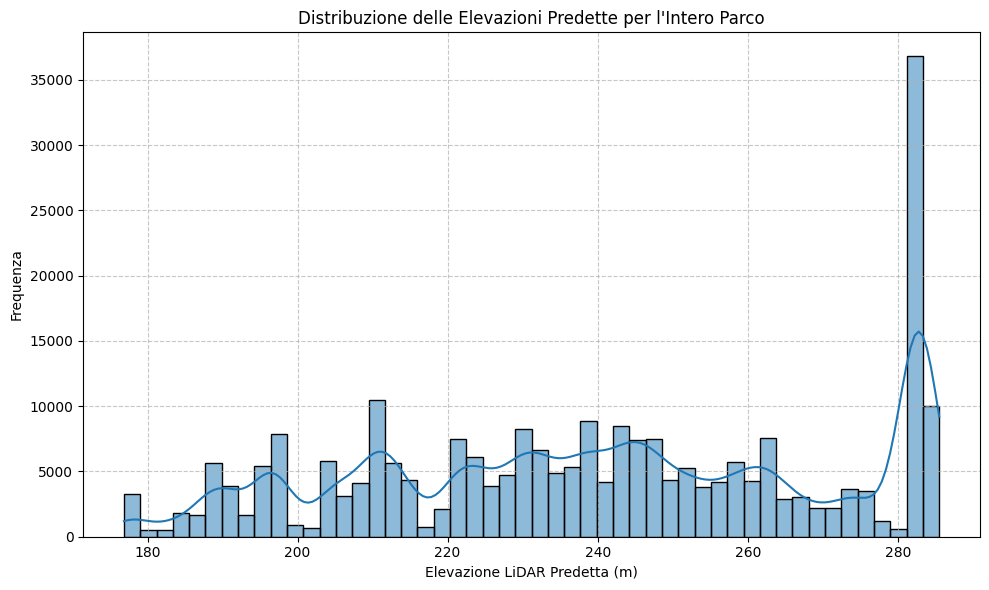

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming valid_predictions is already loaded from the previous step
# If not, you would need to reload it:
# with rasterio.open('/content/LiDAR_prediction_map_full_park.tif') as src:
#     prediction_data = src.read(1)
# valid_predictions = prediction_data[~np.isnan(prediction_data)]

fig = plt.figure(figsize=(10, 6))
sns.histplot(valid_predictions, bins=50, kde=True)
plt.title('Distribuzione delle Elevazioni Predette per l\'Intero Parco')
plt.xlabel('Elevazione LiDAR Predetta (m)')
plt.ylabel('Frequenza')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [33]:
# Ricalcola la media focale per Copernicus DSM e Slope con una finestra 3x3
copernicus_dsm_focal_mean_3x3 = calculate_focal_mean(copernicus_dsm_data, size=3)
slope_focal_mean_3x3 = calculate_focal_mean(slope_data, size=3)

print("Calcolo dei livelli di media focale con finestra 3x3 (i valori NoData sono trattati come NaN e ignorati nel calcolo della media).")

Calcolo dei livelli di media focale con finestra 3x3 (i valori NoData sono trattati come NaN e ignorati nel calcolo della media).


In [34]:
# Crea una maschera completa per il caso 3x3
final_valid_mask_3x3 = (~np.isnan(lidar_data) &
                        ~np.isnan(copernicus_dsm_data) &
                        ~np.isnan(slope_data) &
                        ~np.isnan(aspect_data) &
                        ~np.isnan(tpi_data) &
                        ~np.isnan(ls_data) &
                        ~np.isnan(twi_data) &
                        ~np.isnan(copernicus_dsm_focal_mean_3x3) &
                        ~np.isnan(slope_focal_mean_3x3))

# Applica questa maschera a tutti i dati per il caso 3x3
y_target_3x3 = lidar_data[final_valid_mask_3x3]
X_features_3x3 = np.array([
    copernicus_dsm_data[final_valid_mask_3x3],
    slope_data[final_valid_mask_3x3],
    aspect_data[final_valid_mask_3x3],
    tpi_data[final_valid_mask_3x3],
    ls_data[final_valid_mask_3x3],
    twi_data[final_valid_mask_3x3],
    copernicus_dsm_focal_mean_3x3[final_valid_mask_3x3],
    slope_focal_mean_3x3[final_valid_mask_3x3]
]).T # Trasponi per avere le feature come colonne

print(f"Shape delle feature aggiornate (X) per 3x3: {X_features_3x3.shape}")
print(f"Shape del target aggiornato (y) per 3x3: {y_target_3x3.shape}")

Shape delle feature aggiornate (X) per 3x3: (1487, 8)
Shape del target aggiornato (y) per 3x3: (1487,)


In [35]:
from sklearn.model_selection import train_test_split

# Suddividi i dati in set di training e testing per il caso 3x3
X_train_3x3, X_test_3x3, y_train_3x3, y_test_3x3 = train_test_split(X_features_3x3, y_target_3x3, test_size=0.3, random_state=42)

print(f"Shape di X_train (3x3): {X_train_3x3.shape}")
print(f"Shape di X_test (3x3): {X_test_3x3.shape}")
print(f"Shape di y_train (3x3): {y_train_3x3.shape}")
print(f"Shape di y_test (3x3): {y_test_3x3.shape}")

Shape di X_train (3x3): (1040, 8)
Shape di X_test (3x3): (447, 8)
Shape di y_train (3x3): (1040,)
Shape di y_test (3x3): (447,)


In [36]:
from sklearn.ensemble import RandomForestRegressor

# Inizializza e addestra il modello Random Forest per il caso 3x3
rf_model_3x3 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
print("Addestramento del Random Forest Regressor con feature 3x3...")
rf_model_3x3.fit(X_train_3x3, y_train_3x3)
print("Addestramento 3x3 completato.")

# Ottieni le importanze delle feature per il modello 3x3
feature_names_3x3 = [
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_3x3', 'Slope_FocalMean_3x3'
]
feature_importances_3x3 = pd.Series(rf_model_3x3.feature_importances_, index=feature_names_3x3)
print("Importanza delle Feature per il modello 3x3:")
display(feature_importances_3x3.sort_values(ascending=False))

Addestramento del Random Forest Regressor con feature 3x3...
Addestramento 3x3 completato.
Importanza delle Feature per il modello 3x3:


,0
Copernicus_DSM,0.570674
Copernicus_DSM_FocalMean_3x3,0.419321
TPI,0.002519
Slope_FocalMean_3x3,0.001913
Aspect,0.001541
LS,0.001375
Slope,0.001372
TWI,0.001285


<Figure size 1400x800 with 0 Axes>

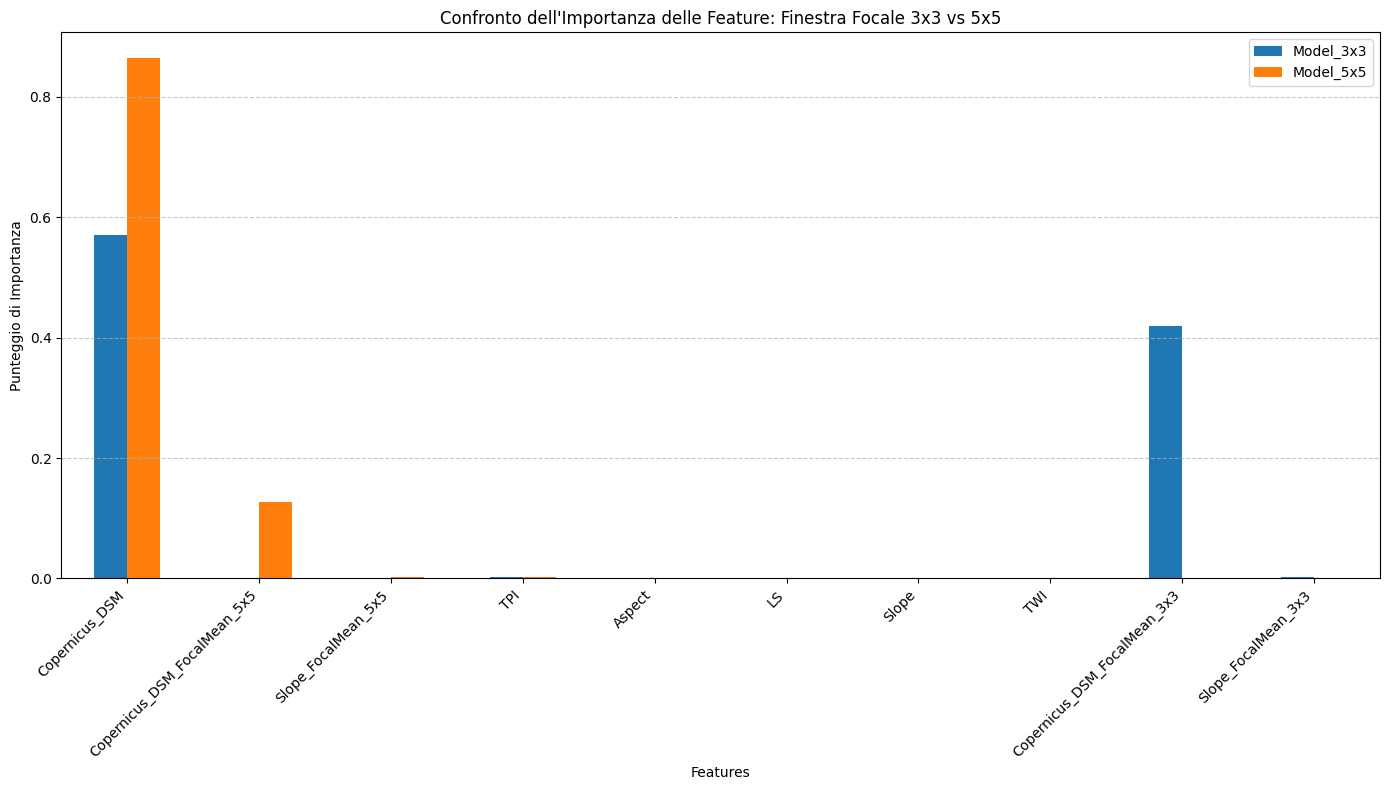

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combina le importanze delle feature dei due modelli per il confronto
comparison_df = pd.DataFrame({
    'Model_3x3': feature_importances_3x3,
    'Model_5x5': feature_importances_updated
}).fillna(0) # Fill NaN with 0 if a feature is not present in one model

# Ordina per l'importanza media o l'importanza in un modello (es. 5x5)
comparison_df = comparison_df.sort_values(by='Model_5x5', ascending=False)

plt.figure(figsize=(14, 8))
comparison_df.plot(kind='bar', figsize=(14, 8))
plt.title('Confronto dell\'Importanza delle Feature: Finestra Focale 3x3 vs 5x5')
plt.xlabel('Features')
plt.ylabel('Punteggio di Importanza')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Esportazione delle Previsioni Finali come GeoTIFF

In [40]:
import rasterio
import numpy as np

# Ricostruisci il raster 2D delle previsioni complete
predicted_2d_map = np.full(lidar_data.shape, np.nan, dtype=lidar_data.dtype)
predicted_2d_map[final_valid_mask] = y_pred_full

# Apri il file LiDAR originale per ottenere i metadati
with rasterio.open(LiDAR_path) as src:
    profile = src.profile

# Aggiorna il profilo per il nuovo file GeoTIFF
profile.update(
    dtype=predicted_2d_map.dtype,
    count=1,
    nodata=np.nan, # Assicurati che i NaN siano scritti come nodata nel GeoTIFF
    tiled=True, # Abilita esplicitamente il tiling
    blockxsize=256, # Imposta una dimensione del blocco multipla di 16
    blockysize=256  # Imposta una dimensione del blocco multipla di 16
)

# Definisci il percorso del file di output
output_geojson_path = '/content/LiDAR_prediction_map.tif'

# Scrivi il nuovo file GeoTIFF
with rasterio.open(output_geojson_path, 'w', **profile) as dst:
    dst.write(predicted_2d_map, 1)

print(f"Mappa delle previsioni esportata con successo in: {output_geojson_path}")

Mappa delle previsioni esportata con successo in: /content/LiDAR_prediction_map.tif


### Cross-Validation per la Valutazione della Stabilità del Modello

In [41]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Re-inizializza il modello Random Forest con gli stessi parametri del modello finale
# rf_model è già stato definito e addestrato con le feature 5x5
model_for_cv = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Configura la strategia di cross-validation (ad esempio, 5 fold)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Esegui la cross-validation per l'R-squared
r2_scores = cross_val_score(model_for_cv, X_features, y_target, cv=kf, scoring='r2', n_jobs=-1)

# Esegui la cross-validation per il Mean Absolute Error (MAE)
# Per MAE, `cross_val_score` restituisce valori negativi per convenzione, quindi prendiamo l'assoluto
mae_scores = -cross_val_score(model_for_cv, X_features, y_target, cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1)

print(f"R-squared (R2) Score per ogni fold: {r2_scores}")
print(f"R-squared (R2) Medio: {r2_scores.mean():.3f} (+/- {r2_scores.std():.3f})")

print(f"\nMean Absolute Error (MAE) per ogni fold: {mae_scores}")
print(f"Mean Absolute Error (MAE) Medio: {mae_scores.mean():.3f} (+/- {mae_scores.std():.3f})")

R-squared (R2) Score per ogni fold: [0.9893933  0.98788565 0.98195467 0.98880423 0.98695187]
R-squared (R2) Medio: 0.987 (+/- 0.003)

Mean Absolute Error (MAE) per ogni fold: [1.71774824 1.68952463 1.9715968  1.52639691 1.81836701]
Mean Absolute Error (MAE) Medio: 1.745 (+/- 0.147)


### Confronto con il Modello XGBoost

In [47]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score

# Inizializza il modello XGBoost Regressor
xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Addestra il modello XGBoost con le feature aggiornate (5x5 focal stats)
print("Addestramento XGBoost Regressor con feature aggiornate...")
xgb_model.fit(X_train, y_train)
print("Addestramento XGBoost completato.")

# Effettua previsioni sul set di test
y_pred_xgb = xgb_model.predict(X_test)

# Valuta il modello XGBoost
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"\nValutazione del modello XGBoost con feature aggiornate:")
print(f"Errore Assoluto Medio (MAE): {mae_xgb:.3f}")
print(f"Coefficiente di Determinazione (R2) Score: {r2_xgb:.3f}")

# Confronto con il Random Forest (dai valori precedentemente calcolati)
print("\nConfronto con il Modello Random Forest:")
print(f"Random Forest MAE: {mae:.3f}")
print(f"Random Forest R2 Score: {r2:.3f}")

Addestramento XGBoost Regressor con feature aggiornate...
Addestramento XGBoost completato.

Valutazione del modello XGBoost con feature aggiornate:
Errore Assoluto Medio (MAE): 1.792
Coefficiente di Determinazione (R2) Score: 0.989

Confronto con il Modello Random Forest:
Random Forest MAE: 1.691
Random Forest R2 Score: 0.989


In [48]:
import pandas as pd

# Identifica i pixel con errori assoluti elevati tra i pixel validi
high_error_threshold = 5
high_error_mask_valid_pixels = np.abs(full_residuals) > high_error_threshold

# Estrai le feature, il target reale e le previsioni per i pixel con errori elevati
X_high_error = X_features[high_error_mask_valid_pixels]
y_target_high_error = y_target[high_error_mask_valid_pixels]
y_pred_high_error = y_pred_full[high_error_mask_valid_pixels]

# Nomi delle feature (assicurati che siano gli stessi usati per X_features)
feature_names = [
    'Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI',
    'Copernicus_DSM_FocalMean_5x5', 'Slope_FocalMean_5x5'
]

# Crea un DataFrame per l'analisi
df_high_error = pd.DataFrame(X_high_error, columns=feature_names)
df_high_error['LiDAR_Elevation_Actual'] = y_target_high_error
df_high_error['LiDAR_Elevation_Predicted'] = y_pred_high_error
df_high_error['Residual_Error'] = df_high_error['LiDAR_Elevation_Actual'] - df_high_error['LiDAR_Elevation_Predicted']

print(f"Numero di pixel con errore assoluto superiore a {high_error_threshold} unità: {len(df_high_error)}")
print("\nStatistiche descrittive per le aree con errori elevati:")
display(df_high_error.describe())

Numero di pixel con errore assoluto superiore a 5 unità: 19

Statistiche descrittive per le aree con errori elevati:


,Copernicus_DSM,Slope,Aspect,TPI,LS,TWI,Copernicus_DSM_FocalMean_5x5,Slope_FocalMean_5x5,LiDAR_Elevation_Actual,LiDAR_Elevation_Predicted,Residual_Error
count,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000
mean,232.197577,12.061737,222.260771,-0.148850,21.722960,6.693222,232.372045,11.628578,221.776932,223.655379,-1.878439
std,30.230314,7.248252,42.314138,4.598388,34.372913,1.586621,28.103202,5.790168,33.125847,31.692788,7.127210
min,191.333160,2.442497,114.422188,-12.227012,0.549682,4.828873,191.812582,3.625937,180.085388,185.612156,-10.297939
25%,209.754105,6.449115,201.037300,-2.195033,2.234363,5.639099,211.716118,6.265882,197.882423,199.896649,-7.073876
50%,219.033646,12.389297,215.824356,-0.291601,5.600721,6.218725,220.361191,13.015024,205.826080,209.189506,-5.582229
75%,255.110420,14.438176,245.669540,2.180076,21.919378,7.176985,252.008636,14.422785,257.690269,250.720718,5.780864
max,283.819611,26.792387,317.240936,6.832953,125.463898,10.567047,279.503723,22.739321,275.430054,281.012283,9.504800


Possiamo anche visualizzare la distribuzione delle feature in queste aree di errore elevato.

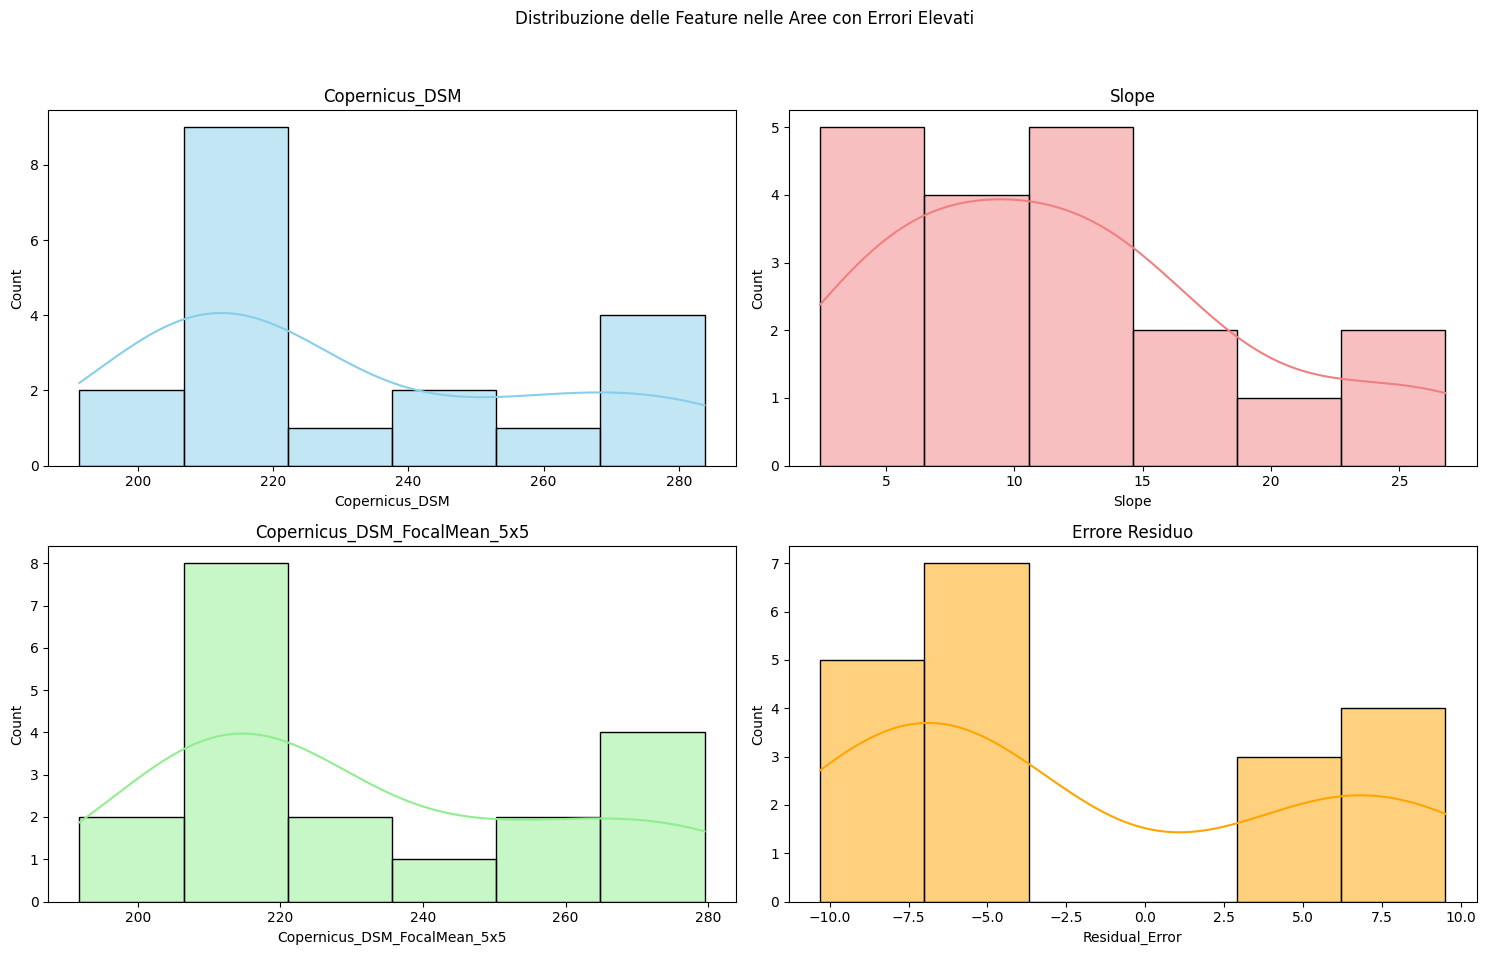

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of key features for high error areas
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Distribuzione delle Feature nelle Aree con Errori Elevati')

sns.histplot(df_high_error['Copernicus_DSM'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Copernicus_DSM')

sns.histplot(df_high_error['Slope'], kde=True, ax=axes[0, 1], color='lightcoral')
axes[0, 1].set_title('Slope')

sns.histplot(df_high_error['Copernicus_DSM_FocalMean_5x5'], kde=True, ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Copernicus_DSM_FocalMean_5x5')

sns.histplot(df_high_error['Residual_Error'], kde=True, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Errore Residuo')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [68]:
output_high_error_stats_path = '/content/high_error_zones_statistics.csv'
df_high_error.to_csv(output_high_error_stats_path, index=False)

print(f"Statistiche delle zone ad alto errore salvate in: {output_high_error_stats_path}")

Statistiche delle zone ad alto errore salvate in: /content/high_error_zones_statistics.csv


### Suddivisione Spaziale del Dataset

Procediamo con una suddivisione spaziale, dividendo il dataset in base alla coordinata X (longitudine) dei pixel validi. Questo creerà un set di training e un set di test geograficamente distinti, permettendoci di valutare la capacità di generalizzazione del modello in aree non viste.

In [52]:
# 1. Ottieni gli indici di riga e colonna dei pixel validi
rows, cols = np.where(final_valid_mask)

# 2. Converti gli indici di riga/colonna in coordinate geografiche (x, y)
x_coords, y_coords = rasterio.transform.xy(lidar_transform, rows, cols)

# 3. Combina le coordinate con X_features e y_target
coords_df = pd.DataFrame({
    'x': x_coords,
    'y': y_coords,
    'original_index': np.arange(len(x_coords)) # Mappa agli indici di X_features/y_target
})

# 4. Definisci il criterio di split spaziale (es. mediana della coordinata x)
median_x = coords_df['x'].median()

# 5. Crea le maschere spaziali per training e test
# Per esempio, metà ovest per il training, metà est per il test
spatial_train_indices = coords_df[coords_df['x'] <= median_x]['original_index'].values
spatial_test_indices = coords_df[coords_df['x'] > median_x]['original_index'].values

# 6. Applica le maschere spaziali per creare X_train_spatial, y_train_spatial, ecc.
X_train_spatial = X_features[spatial_train_indices]
X_test_spatial = X_features[spatial_test_indices]
y_train_spatial = y_target[spatial_train_indices]
y_test_spatial = y_target[spatial_test_indices]

print(f"Numero totale di pixel validi: {len(X_features)}")
print(f"Pixel nel set di training spaziale: {len(X_train_spatial)}")
print(f"Pixel nel set di test spaziale: {len(X_test_spatial)}")

print(f"\nShape di X_train_spatial: {X_train_spatial.shape}")
print(f"Shape di y_train_spatial: {y_train_spatial.shape}")
print(f"Shape di X_test_spatial: {X_test_spatial.shape}")
print(f"Shape di y_test_spatial: {y_test_spatial.shape}")

Numero totale di pixel validi: 1487
Pixel nel set di training spaziale: 780
Pixel nel set di test spaziale: 707

Shape di X_train_spatial: (780, 8)
Shape di y_train_spatial: (780,)
Shape di X_test_spatial: (707, 8)
Shape di y_test_spatial: (707,)


Ora che abbiamo i set di training e test suddivisi spazialmente, possiamo procedere a ri-addestrare e valutare il modello con questa nuova configurazione. Vuoi procedere con l'addestramento del modello Random Forest o XGBoost con questa suddivisione spaziale?

### Implementazione della Block Cross-Validation

Implementiamo la Block Cross-Validation dividendo l'area in blocchi di 90m x 90m (3x3 pixel). Utilizzeremo `GroupKFold` per garantire che i pixel all'interno dello stesso blocco siano sempre assegnati allo stesso set (training o test) in ogni fold, fornendo una valutazione più realistica della generalizzazione spaziale del modello.

In [51]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# --- 1. Definire la dimensione del blocco in pixel ---
# Blocco di 100m x 100m --> 100m / 30m/pixel = 3.33 pixel
# Utilizziamo un blocco di 3x3 pixel (90m x 90m) come approssimazione.
block_size_pixels = 3

# --- 2. Assegnare a ciascun pixel valido un ID di blocco ---
# Ottieni gli indici di riga e colonna dei pixel validi
rows_valid, cols_valid = np.where(final_valid_mask)

# Calcola gli indici dei blocchi per ciascun pixel valido
block_row_idx = rows_valid // block_size_pixels
block_col_idx = cols_valid // block_size_pixels

# Crea un ID di blocco unico per ciascun blocco
# max_block_cols è il numero massimo di colonne di blocco possibili nell'intero raster
max_block_cols = (lidar_data.shape[1] // block_size_pixels) + 1
block_ids = (block_row_idx * max_block_cols) + block_col_idx

print(f"Numero di pixel validi: {len(X_features)}")
print(f"Numero di blocchi unici identificati: {len(np.unique(block_ids))}")

# --- 3. Eseguire la Block Cross-Validation ---

# Re-inizializza il modello Random Forest
rf_model_block_cv = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Configura GroupKFold
# Utilizziamo 5 fold, assicurando che i gruppi (blocchi) siano divisi correttamente
gkf = GroupKFold(n_splits=5)

r2_scores_block_cv = []
mae_scores_block_cv = []

print("\nEsecuzione della Block Cross-Validation...")
for fold, (train_idx, test_idx) in enumerate(gkf.split(X_features, y_target, groups=block_ids)):
    X_train_fold, X_test_fold = X_features[train_idx], X_features[test_idx]
    y_train_fold, y_test_fold = y_target[train_idx], y_target[test_idx]

    rf_model_block_cv.fit(X_train_fold, y_train_fold)
    y_pred_fold = rf_model_block_cv.predict(X_test_fold)

    r2_scores_block_cv.append(r2_score(y_test_fold, y_pred_fold))
    mae_scores_block_cv.append(mean_absolute_error(y_test_fold, y_pred_fold))

print("Block Cross-Validation completata.")

print(f"\nRisultati Block Cross-Validation (Random Forest):")
print(f"R-squared (R2) Score per ogni fold: {r2_scores_block_cv}")
print(f"R-squared (R2) Medio: {np.mean(r2_scores_block_cv):.3f} (+/- {np.std(r2_scores_block_cv):.3f})")

print(f"Mean Absolute Error (MAE) per ogni fold: {mae_scores_block_cv}")
print(f"Mean Absolute Error (MAE) Medio: {np.mean(mae_scores_block_cv):.3f} (+/- {np.std(mae_scores_block_cv):.3f})")

Numero di pixel validi: 1487
Numero di blocchi unici identificati: 189

Esecuzione della Block Cross-Validation...
Block Cross-Validation completata.

Risultati Block Cross-Validation (Random Forest):
R-squared (R2) Score per ogni fold: [0.9774971325428132, 0.9729041093520989, 0.9886011659917453, 0.9877999843910054, 0.9894273482535887]
R-squared (R2) Medio: 0.983 (+/- 0.007)
Mean Absolute Error (MAE) per ogni fold: [2.295565445663145, 2.0769261620028705, 1.7216688964021734, 2.0079894783199843, 1.6019562425195968]
Mean Absolute Error (MAE) Medio: 1.941 (+/- 0.250)


I risultati della Block Cross-Validation forniscono una stima più robusta delle prestazioni del modello su dati geograficamente non visti. Un calo delle metriche (come R2 o un aumento del MAE) rispetto alla cross-validation casuale sarebbe atteso e indicherebbe la presenza di autocorrelazione spaziale che il modello fatica a generalizzare oltre i blocchi di training.

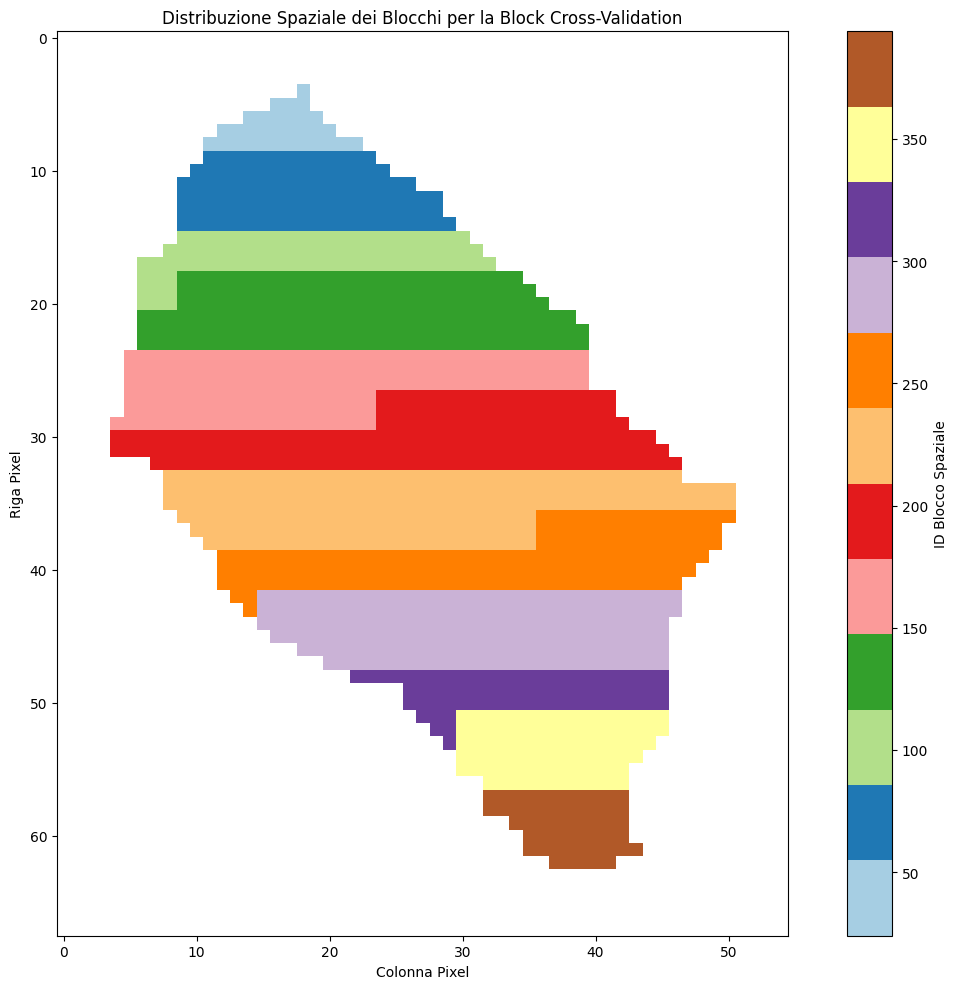

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Create an empty 2D array to store block IDs, same shape as original raster
block_map = np.full(lidar_data.shape, np.nan, dtype=float)

# Fill the 2D array with block_ids at the positions of valid pixels
block_map[rows_valid, cols_valid] = block_ids

plt.figure(figsize=(12, 10))
plt.imshow(block_map, cmap='Paired', origin='upper') # 'Paired' colormap is good for discrete categories
plt.colorbar(label='ID Blocco Spaziale')
plt.title('Distribuzione Spaziale dei Blocchi per la Block Cross-Validation')
plt.xlabel('Colonna Pixel')
plt.ylabel('Riga Pixel')
plt.tight_layout()
plt.show()

In [71]:
import rasterio
import numpy as np

# Apri il file LiDAR originale per ottenere i metadati (in particolare il CRS e il transform)
with rasterio.open(LiDAR_path) as src:
    profile_block_map = src.profile

# Aggiorna il profilo per il nuovo file GeoTIFF della mappa dei blocchi
profile_block_map.update(
    dtype=block_map.dtype,
    count=1,
    nodata=np.nan, # Assicurati che i NaN siano scritti come nodata nel GeoTIFF
    tiled=True, # Abilita esplicitamente il tiling
    blockxsize=256, # Imposta una dimensione del blocco multipla di 16
    blockysize=256
)

# Definisci il percorso del file di output per la mappa dei blocchi
output_block_map_path = '/content/spatial_block_map.tif'

# Scrivi il nuovo file GeoTIFF
with rasterio.open(output_block_map_path, 'w', **profile_block_map) as dst:
    dst.write(block_map, 1)

print(f"Mappa dei blocchi spaziali esportata con successo in: {output_block_map_path}")

Mappa dei blocchi spaziali esportata con successo in: /content/spatial_block_map.tif


### Confronto tra Validazione Standard e Block Cross-Validation

Abbiamo eseguito due tipi di cross-validation per valutare la stabilità e la capacità di generalizzazione del modello:

1.  **Validazione K-Fold Standard (Casuale):** Questo metodo suddivide casualmente i dati in *k* fold, garantendo che ogni punto dati appaia esattamente una volta nel set di test. È utile per valutare la performance media del modello su un dataset distribuito in modo uniforme, ma potrebbe sovrastimare la performance in scenari spaziali a causa dell'autocorrelazione.

2.  **Block Cross-Validation (Spaziale):** Questo metodo raggruppa i dati in blocchi spaziali e garantisce che i punti dati all'interno dello stesso blocco siano sempre mantenuti insieme (nel training o nel test set). Questo è cruciale per i dati geospaziali, in quanto tiene conto dell'autocorrelazione spaziale. I risultati da questa metodologia sono generalmente considerati una stima più robusta della capacità di generalizzazione del modello su aree geograficamente non viste.

Analizziamo le metriche medie ottenute da entrambi i metodi per il modello Random Forest:

,Metodo di Validazione,MAE Medio,Std MAE,R2 Medio,Std R2
0,Standard K-Fold CV,1.744727,0.147198,0.986998,0.002654
1,Block K-Fold CV,1.940821,0.249695,0.983246,0.006747


/tmp/ipykernel_763/859069513.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metodo di Validazione', y='MAE Medio', data=results_df, ax=axes[0], palette='coolwarm')
/tmp/ipykernel_763/859069513.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metodo di Validazione', y='R2 Medio', data=results_df, ax=axes[1], palette='coolwarm')


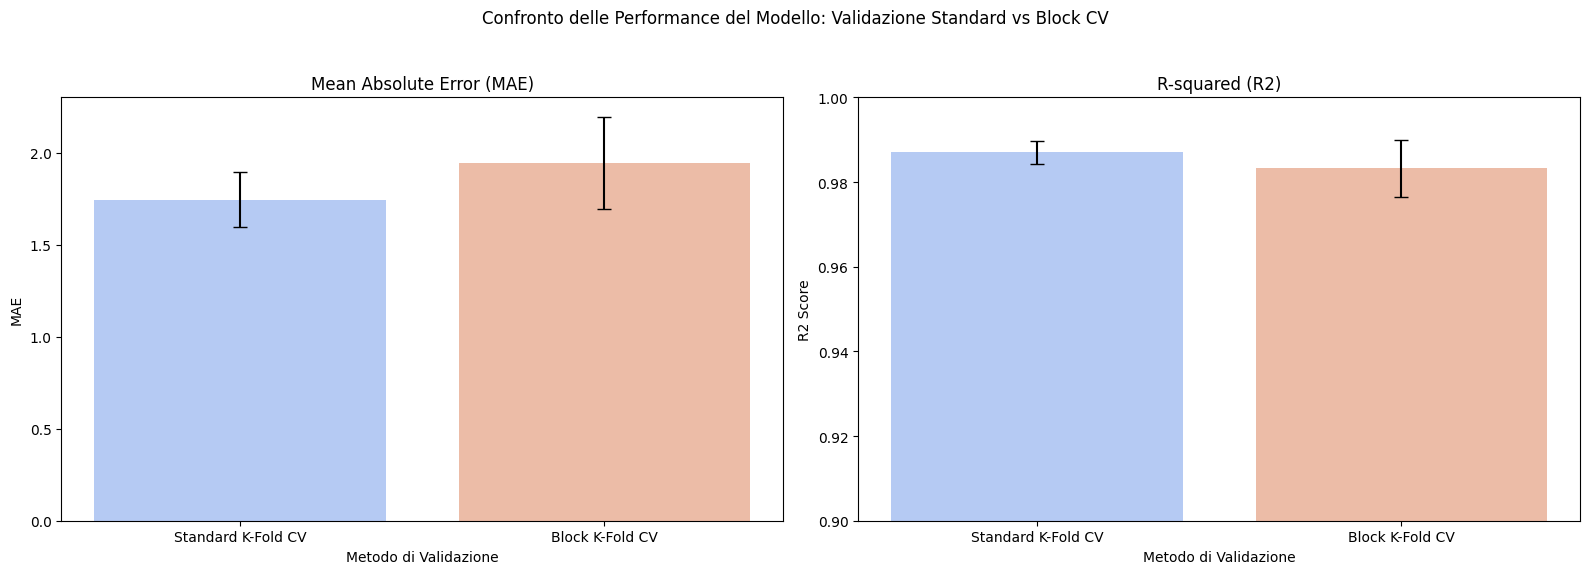

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Recupera i risultati dal kernel
# Standard KFold CV results
mean_r2_standard = np.mean(r2_scores)
std_r2_standard = np.std(r2_scores)
mean_mae_standard = np.mean(mae_scores)
std_mae_standard = np.std(mae_scores)

# Block KFold CV results
mean_r2_block = np.mean(r2_scores_block_cv)
std_r2_block = np.std(r2_scores_block_cv)
mean_mae_block = np.mean(mae_scores_block_cv)
std_mae_block = np.std(mae_scores_block_cv)

# Crea un DataFrame per i risultati
results_data = {
    'Metodo di Validazione': ['Standard K-Fold CV', 'Block K-Fold CV'],
    'MAE Medio': [mean_mae_standard, mean_mae_block],
    'Std MAE': [std_mae_standard, std_mae_block],
    'R2 Medio': [mean_r2_standard, mean_r2_block],
    'Std R2': [std_r2_standard, std_r2_block]
}
results_df = pd.DataFrame(results_data)

display(results_df)

# Visualizzazione
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Confronto delle Performance del Modello: Validazione Standard vs Block CV')

# Bar plot per MAE
sns.barplot(x='Metodo di Validazione', y='MAE Medio', data=results_df, ax=axes[0], palette='coolwarm')
axes[0].errorbar(x=results_df['Metodo di Validazione'], y=results_df['MAE Medio'], yerr=results_df['Std MAE'], fmt='none', c='black', capsize=5)
axes[0].set_title('Mean Absolute Error (MAE)')
axes[0].set_ylabel('MAE')

# Bar plot per R2
sns.barplot(x='Metodo di Validazione', y='R2 Medio', data=results_df, ax=axes[1], palette='coolwarm')
axes[1].errorbar(x=results_df['Metodo di Validazione'], y=results_df['R2 Medio'], yerr=results_df['Std R2'], fmt='none', c='black', capsize=5)
axes[1].set_title('R-squared (R2)')
axes[1].set_ylabel('R2 Score')
axes[1].set_ylim(0.9, 1.0) # Imposta un limite y per rendere più evidenti le differenze di R2

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [72]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [73]:
# Define the Google Drive folder path
drive_output_folder = '/content/drive/My Drive/Output_Modello_LiDAR'

# Create the folder if it doesn't exist
import os
if not os.path.exists(drive_output_folder):
    os.makedirs(drive_output_folder)
    print(f"Cartella creata: {drive_output_folder}")
else:
    print(f"La cartella esiste già: {drive_output_folder}")

Cartella creata: /content/drive/My Drive/Output_Modello_LiDAR


In [74]:
# List of generated files to copy
output_files = [
    '/content/LiDAR_prediction_map.tif',
    '/content/model_comparison_metrics.csv',
    '/content/high_error_zones_statistics.csv',
    '/content/spatial_block_map.tif'
]

# Copy each file to Google Drive
for file_path in output_files:
    if os.path.exists(file_path):
        file_name = os.path.basename(file_path)
        destination_path = os.path.join(drive_output_folder, file_name)
        !cp "{file_path}" "{destination_path}"
        print(f"Copiato '{file_name}' in '{drive_output_folder}'")
    else:
        print(f"Attenzione: File non trovato '{file_path}', non può essere copiato.")

print("Tutti i file specificati sono stati elaborati.")

Copiato 'LiDAR_prediction_map.tif' in '/content/drive/My Drive/Output_Modello_LiDAR'
Copiato 'model_comparison_metrics.csv' in '/content/drive/My Drive/Output_Modello_LiDAR'
Copiato 'high_error_zones_statistics.csv' in '/content/drive/My Drive/Output_Modello_LiDAR'
Copiato 'spatial_block_map.tif' in '/content/drive/My Drive/Output_Modello_LiDAR'
Tutti i file specificati sono stati elaborati.


In [26]:
import os
import shutil

# Define the Google Drive folder path
drive_output_folder = '/content/drive/My Drive/Output_Modello_LiDAR'

# Create a temporary local directory to stage files
temp_local_dir = '/content/temp_drive_upload'
if not os.path.exists(temp_local_dir):
    os.makedirs(temp_local_dir)
    print(f"Cartella temporanea creata: {temp_local_dir}")

# List all files and directories in /content
content_items = os.listdir('/content')

# Filter for actual files (not directories) and exclude hidden/system files
files_to_copy = [
    item for item in content_items
    if os.path.isfile(os.path.join('/content', item))
    and not item.startswith('.')
    and item != 'gdrive'
    and not item.startswith('sample_data') # Exclude sample_data folder contents
]

print("Copiando i file nella cartella temporanea locale...")

# Copy each file from /content to the temporary local directory
for file_name in files_to_copy:
    source_path = os.path.join('/content', file_name)
    destination_path_temp = os.path.join(temp_local_dir, file_name)
    try:
        shutil.copy2(source_path, destination_path_temp) # Use copy2 to preserve metadata
        # print(f"Copiato '{file_name}' nella cartella temporanea.") # Optional: too verbose
    except Exception as e:
        print(f"Errore durante la copia locale di '{file_name}': {e}")

print("Copia locale completata. Ora copio la cartella temporanea in Google Drive...")

# Copy the entire temporary local directory to Google Drive recursively
try:
    # Ensure the destination folder in Drive exists (it should, from previous steps)
    if not os.path.exists(drive_output_folder):
        os.makedirs(drive_output_folder)
        print(f"Cartella Drive creata: {drive_output_folder}")

    # Use !cp -r to copy the temporary folder's *contents* to the Drive folder
    !cp -r "{temp_local_dir}"/* "{drive_output_folder}"/
    print(f"Contenuti della cartella temporanea copiati in: {drive_output_folder}")
except Exception as e:
    print(f"Errore durante la copia della cartella in Google Drive: {e}")

# Clean up the temporary local directory
try:
    shutil.rmtree(temp_local_dir)
    print(f"Cartella temporanea eliminata: {temp_local_dir}")
except Exception as e:
    print(f"Errore durante l'eliminazione della cartella temporanea: {e}")

print("Copia di tutti i file completata.")

Cartella temporanea creata: /content/temp_drive_upload
Copiando i file nella cartella temporanea locale...
Copia locale completata. Ora copio la cartella temporanea in Google Drive...
Cartella Drive creata: /content/drive/My Drive/Output_Modello_LiDAR
Contenuti della cartella temporanea copiati in: /content/drive/My Drive/Output_Modello_LiDAR
Cartella temporanea eliminata: /content/temp_drive_upload
Copia di tutti i file completata.


In [55]:
output_csv_path = '/content/model_comparison_metrics.csv'
results_df.to_csv(output_csv_path, index=False)

print(f"Metriche di confronto salvate in: {output_csv_path}")

Metriche di confronto salvate in: /content/model_comparison_metrics.csv


In [4]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (1040, 6)
Shape of X_test: (447, 6)
Shape of y_train: (1040,)
Shape of y_test: (447,)


In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Initialize the Random Forest Regressor model
# You can tune hyperparameters like n_estimators, max_depth, etc.
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 uses all available processors

# Train the model
print("Training Random Forest Regressor...")
rf_model.fit(X_train, y_train)
print("Training complete.")

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nModel Evaluation:")
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"R-squared (R2) Score: {r2:.3f}")

# Optionally, display feature importances
feature_importances = pd.Series(rf_model.feature_importances_, index=['Copernicus_DSM', 'Slope', 'Aspect', 'TPI', 'LS', 'TWI'])
print("\nFeature Importances:")
display(feature_importances.sort_values(ascending=False))

Training Random Forest Regressor...
Training complete.

Model Evaluation:
Mean Absolute Error (MAE): 1.773
R-squared (R2) Score: 0.988

Feature Importances:


,0
Copernicus_DSM,0.987492
TPI,0.004495
Slope,0.002280
TWI,0.001995
LS,0.001924
Aspect,0.001815


/tmp/ipykernel_763/2891190768.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.index, y=feature_importances.values, palette='viridis')


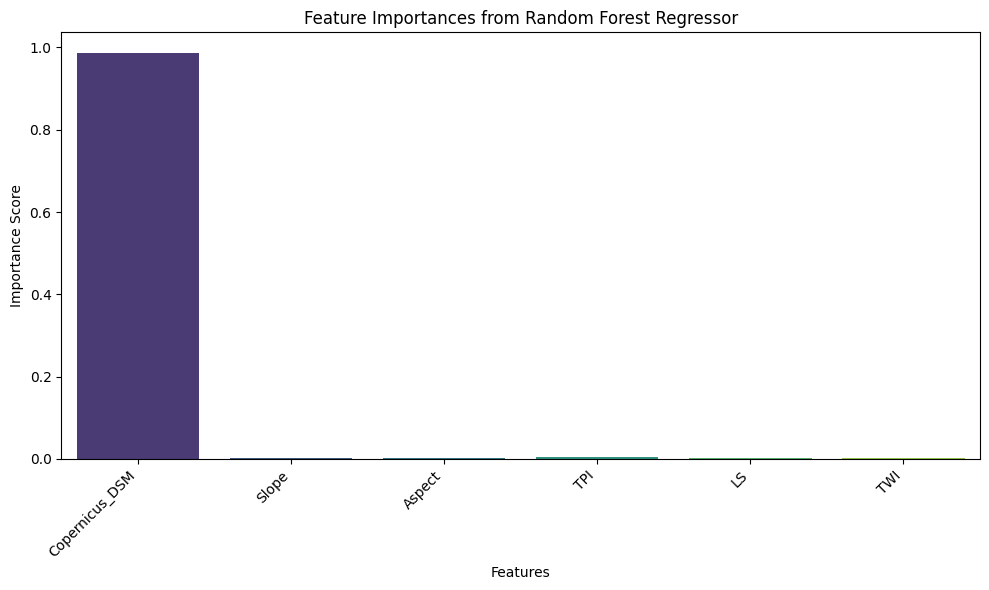

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.index, y=feature_importances.values, palette='viridis')
plt.title('Feature Importances from Random Forest Regressor')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout()
plt.show()